# Eligibility-trace control and off-policy learning: implementation

Sarsa($\lambda$) with its three trace types, Watkins's Q($\lambda$) and the variable-$\lambda$ return, on a windy gridworld whose exact optimum is known and on small cases whose traces are worked out by hand.
Companion to the chapter note: [Eligibility-trace control and off-policy](../chapters/07b%20Eligibility-trace%20control%20and%20off-policy.md).

Not implemented, and why:
- **Off-policy traces with importance sampling:** the chapter only motivates this direction and gives no algorithm.
- **Implementation issues** (keeping only the few nonzero traces, the cost of traces): the notebook keeps dense traces and measures no computing cost.
- **Conclusions about non-Markov tasks and scarce data:** the notebook has no task that tests them.

**Sections**
1. The gridworlds and the exact answers
2. Sarsa($\lambda$): the update, the three trace types and hand-checked cases
3. What one episode strengthens
4. Sarsa($\lambda$) on the windy gridworld
5. Watkins's Q($\lambda$)
6. Frequent exploration cuts the traces
7. Variable $\lambda$
8. Checkpoints

In [1]:
from math import comb
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})

SEED_ZERO, SEED_WINDY, SEED_WATKINS, SEED_EQUIV, SEED_EPS, SEED_POLICY, SEED_VARIABLE = 71, 72, 73, 74, 75, 76, 77
UP, DOWN, RIGHT, LEFT = range(4)
MOVES = ((-1, 0), (1, 0), (0, 1), (0, -1))  # (row, column) change of up, down, right, left
ACTION_OF = {"U": UP, "D": DOWN, "R": RIGHT, "L": LEFT}
GAMMA = 1.0  # the control tasks are undiscounted, as in the chapter's examples; the identity checks below set their own discounts
EXACT_TOL = 1e-12  # exact arithmetic on at most a few hundred operations: rounding stays below 1e-14
VALUE_TOL = 1e-12  # value iteration stops when no value changes by more than this
N_POLICY_DRAWS = 200_000  # draws in the epsilon-greedy selection check
Z_LIMIT = 4  # standard errors allowed for a single sampled comparison
N_COMPARISONS, FAMILY_ALPHA = 33, 0.05  # sampled comparisons asserted below and the family-wise false-alarm chance allowed for all of them
OPTIMUM_TOL, LENGTH_TOL, TRACE_LIMIT_TOL = 1e-9, 1e-8, 1e-9  # value-iteration optimum, linear-solve agreement, geometric trace limits
BAR_WIDTH, Q_ROW = 0.4, (0.3, 0.1, 0.2, 0.0)  # bar width of the weights plot; action values of the selection check (one clear maximizer)
RANDOM_GRID, CHAIN_COLS = 3, 3  # side of the grid of the random trajectories; cells of the one-row corridor
REVISIT_ALPHA, REVISIT_LAMBDA = 0.5, 0.5  # step size and trace decay of the revisited-pair check
HAND_GREEDY = (True, True, False, True)  # whether A_t is greedy in the chapter note's four-step table, t = 0..3 (t = 0 is irrelevant: traces start at 0)

TRACE_ROWS, TRACE_COLS = 8, 10  # the gridworld of the one-episode picture
TRACE_START, TRACE_GOAL = (5, 0), (4, 6)
TRACE_PATH = "RRRUURRRRDDDLUU"  # 15 moves from start to the rewarded cell, no state-action pair repeated
ALPHA_PATH, LAMBDA_PATH = 0.5, 0.9

DATASET_ALPHA, DATASET_LAMBDA = 0.5, 0.5  # the four-step episode of the chapter note, gamma = 1
N_PATHS, PATH_ALPHA, PATH_GAMMA, PATH_LAMBDA = 300, 0.3, 0.9, 0.8  # random trajectories for the equation check

WIND = (0, 0, 0, 1, 1, 1, 2, 2, 1, 0)  # upward push per column of the windy gridworld
WINDY_ROWS, WINDY_START, WINDY_GOAL = 7, (3, 0), (3, 7)
ALPHA, EPS = 0.5, 0.1  # the windy gridworld's step size and exploration rate
N_RUNS, N_EPISODES, N_LAST = 100, 100, 20  # runs, episodes per run, and the final window of episodes
LAMBDAS = (0.0, 0.3, 0.6, 0.8, 0.9, 0.95, 0.99)
LAMBDA = 0.9  # the trace decay used in the method comparisons
LAMBDA_NEAR_BEST = 0.8  # the sweep value compared with LAMBDA; picked after seeing that it came close (post hoc), so its comparison is descriptive
LAMBDAS_PLOTTED = (0.0, 0.6, LAMBDA)  # the values drawn as curves
N_RUNS_TYPES, N_EPISODES_TYPES = 100, 40  # smaller scale for the trace-type comparison (accumulating traces diverge)
GREEDY_CAP, OPTIMAL_STEPS = 200, 15  # step cap when following a greedy policy; the optimum of the windy gridworld, checked against value iteration
MAX_EPISODE_STEPS = 5000  # step cap of one episode in `run_control`
EPS_GRID = (0.05, 0.1, 0.2, 0.4, 0.6)
CUT_DELTA = 1e-6  # failure probability of the Hoeffding limit on the share of cut steps

VAR_T, VAR_STATES, VAR_GAMMA, N_EPISODES_VAR = 12, 5, 0.9, 200  # variable-lambda episodes: length, states, discount, count
VAR_LAMBDA, VAR_CONFIDENT_STEP = 0.9, 4  # constant lambda of the weights illustration, and the step at which the second case sets lambda to 0

## 1. The gridworlds and the exact answers

Both tasks are deterministic gridworlds with four moves (up, down, right, left); a move off the grid leaves the agent where it is. Rows are counted from the top, starting at 0.

- **Windy gridworld**, rebuilt from the description in the previous chapter (its parameters, the minimum of 15 steps, the figure of about 17 steps and the example of a left move next to the goal below all come from that chapter, not from the pages this notebook covers): 7 rows and 10 columns, start in row 3 column 0, goal in row 3 column 7. An upward wind of 0, 0, 0, 1, 1, 1, 2, 2, 1, 0 cells in the columns 0 to 9 shifts the result of every move, using the wind of the column the agent was in before the move. The reward is $-1$ on every step (including the step into the goal) and the task is undiscounted ($\gamma = 1$), so the return is minus the number of steps.
- **Empty gridworld** (the section on what one episode strengthens): 8 rows and 10 columns, no wind, reward 0 everywhere except 1 on entering the goal.

An **$\varepsilon$-greedy** policy takes a uniformly random action with probability $\varepsilon$ and otherwise a **greedy** action, one that maximizes $Q$. A random pick can coincide with the greedy action. An action that is not a maximizer is called **exploratory** (non-greedy); an action that ties for the maximum counts as greedy. The chapter leaves open how to break ties among several maximizers; here the choice is uniform at random. With one maximizer, a step ends in a non-greedy action with probability $\frac{3}{4}\varepsilon$: the random pick (probability $\varepsilon$) must land on one of the three other actions of four. With several maximizers the probability is lower.

The exact answers used as truth:

$$
V(s) \leftarrow \max_a \big[ r(s,a) + \gamma V(s') \big] \;\; \text{(value iteration)}, \qquad
V(s) \leftarrow (1-\varepsilon) \max_a q(s,a) + \varepsilon \, \tfrac{1}{4} \textstyle\sum_a q(s,a) \;\; \text{(best } \varepsilon\text{-greedy-class behaviour)}
$$

- The first gives the optimal values $v_*$ and action values $q_*$; minus $v_*$ at the start is the fewest steps possible.
- The second gives the best expected return of any behaviour that is $\varepsilon$-greedy with respect to some action values. A learner that behaves $\varepsilon$-greedily with respect to its own $Q$ cannot beat it, so it is a floor for the steps per episode of every run below.
- As a second route, the expected number of steps of the policy that is $\varepsilon$-greedy with respect to the second computation's $q$ is also found by solving the linear equations of policy evaluation.

In [2]:
class World(NamedTuple):
    """A deterministic gridworld: `next_state[s, a]`, `reward[s, a]`, the start and goal state indices and the grid shape."""

    next_state: np.ndarray
    reward: np.ndarray
    start: int
    goal: int
    shape: tuple[int, int]


def build_world(rows: int, cols: int, wind: tuple, start: tuple, goal: tuple, goal_reward: float, step_reward: float) -> World:
    """Gridworld with an upward wind per column; the wind of the current column shifts the result of every move."""
    nxt = np.zeros((rows * cols, 4), int)
    for r in range(rows):
        for c in range(cols):
            for a, (dr, dc) in enumerate(MOVES):
                nxt[r * cols + c, a] = min(max(r + dr - wind[c], 0), rows - 1) * cols + min(max(c + dc, 0), cols - 1)
    g = goal[0] * cols + goal[1]
    reward = np.where(nxt == g, goal_reward, step_reward)
    nxt[g], reward[g] = g, 0.0
    return World(nxt, reward, start[0] * cols + start[1], g, (rows, cols))

In [3]:
def soft_optimal_values(w: World, eps: float, gamma: float = GAMMA) -> tuple[np.ndarray, np.ndarray]:
    """Value iteration for the best epsilon-greedy-class behaviour: V(s) = (1-eps) max_a q + eps mean_a q. eps = 0 gives v_* and q_*. Returns (V, q)."""
    V = np.zeros(len(w.next_state))
    while True:
        q = w.reward + gamma * V[w.next_state]
        V_new = (1 - eps) * q.max(1) + eps * q.mean(1)
        V_new[w.goal] = 0.0
        done = np.abs(V_new - V).max() < VALUE_TOL
        V = V_new
        if done:
            return V, w.reward + gamma * V[w.next_state]


def policy_length(w: World, Q: np.ndarray, eps: float) -> np.ndarray:
    """Exact expected steps from the start of the epsilon-greedy policy (ties share the greedy probability) for each action-value table in `Q[run, s, a]`."""
    is_max = Q >= Q.max(-1, keepdims=True)
    pi = eps / Q.shape[-1] + (1 - eps) * is_max / is_max.sum(-1, keepdims=True)
    onehot = np.eye(len(w.next_state))[w.next_state]
    keep = np.arange(len(w.next_state)) != w.goal
    P = np.einsum("rsa,sat->rst", pi, onehot)[:, keep][:, :, keep]
    T = np.linalg.solve(np.eye(keep.sum()) - P, np.ones((len(Q), keep.sum(), 1)))[..., 0]
    return T[:, int(keep[: w.start].sum())]

In [4]:
windy = build_world(WINDY_ROWS, len(WIND), WIND, WINDY_START, WINDY_GOAL, -1.0, -1.0)
V_opt, q_opt = soft_optimal_values(windy, 0.0)
V_soft, q_soft = soft_optimal_values(windy, EPS)
length_gap = abs(policy_length(windy, q_soft[None], EPS)[0] + V_soft[windy.start])
right_of_goal = WINDY_GOAL[0] * len(WIND) + WINDY_GOAL[1] + 1
print(f"Optimal steps from the start: {-V_opt[windy.start]:.0f}; best epsilon-greedy-class policy at epsilon = {EPS}: {-V_soft[windy.start]:.3f} steps")
print(f"The same optimum from a linear solve of the induced policy differs by {length_gap:.1e}")
print("Left from the cell right of the goal lands on cell (row, column):", divmod(int(windy.next_state[right_of_goal, LEFT]), len(WIND)))
print("Checkpoint: the optimum is 15 steps and the wind moves the agent as the book's example describes")

Optimal steps from the start: 15; best epsilon-greedy-class policy at epsilon = 0.1: 17.048 steps
The same optimum from a linear solve of the induced policy differs by 1.2e-12
Left from the cell right of the goal lands on cell (row, column): (2, 7)
Checkpoint: the optimum is 15 steps and the wind moves the agent as the book's example describes


### Reading the result

- Value iteration gives 15 steps from the start, the minimum the book states for this task.
- The best $\varepsilon$-greedy-class behaviour at $\varepsilon = 0.1$ needs 17.048 steps on average. The book reports that its Sarsa run settled near 17 steps under continued exploration; the exact floor agrees with that to the precision the book gives.
- The linear solve for the same policy differs from the value-iteration answer by 1.2e-12, so the two routes agree.
- A left move from the cell right of the goal lands on row 2 column 7, the cell just above the goal, exactly the example the book gives.

## 2. Sarsa($\lambda$): the update, the three trace types and hand-checked cases

Sarsa($\lambda$) runs temporal-difference (TD) learning with eligibility traces on state-action pairs. (Sarsa is named after the five quantities of its update: state, action, reward, next state, next action.) A TD update moves a value toward a target built from the next estimate. A trace $E(s,a)$ records how recently and how often each pair was visited, and each step's TD error is spread over all pairs in proportion to their traces.

One step from $S$ with action $A$: observe $R$ and $S'$, choose $A'$ from $S'$ ($\varepsilon$-greedy with respect to $Q$), then

$$
\delta = R + \gamma Q(S', A') - Q(S, A), \qquad
E(S,A) \leftarrow \begin{cases} E(S,A) + 1 & \text{accumulating} \\ (1-\alpha) E(S,A) + 1 & \text{dutch} \\ 1 & \text{replacing} \end{cases}, \qquad
Q \leftarrow Q + \alpha \delta E, \quad E \leftarrow \gamma \lambda E
$$

where the last two updates apply to every pair, $\alpha$ is the step size and $\lambda$ the trace decay. In words: an accumulating trace adds 1 on each visit; a replacing trace is reset to 1; a dutch trace is first shrunk by the factor $1-\alpha$ and then incremented by 1, so repeated visits add less than 1. The TD error uses the next action actually chosen, so the method is on-policy: it estimates $q_\pi$ of the policy it follows while that policy becomes greedier. With $\lambda = 0$ every trace is zero after its step, which is **one-step Sarsa**.

One function, `trace_step`, performs the box for many independent runs at once; the same function serves the hand-checked cases, so those checks test the code the experiments use. Its `method` argument also covers Watkins's Q($\lambda$) (the Watkins's Q($\lambda$) section).

Where the toy differs from the book or fills a gap in it:
- $Q$ starts at 0 (the windy example's choice) and the box's order is kept: $A'$ and $\delta$ are computed before the update.
- - **Dutch traces, box against equation.** The printed box shrinks only the visited pair's trace by $1-\alpha$ ($E \leftarrow (1-\alpha)E + 1$), then every pair decays by $\gamma\lambda$. The chapter's equation puts $1-\alpha$ into the decay of every pair, $E_t = (1-\alpha)\gamma\lambda E_{t-1} + I$, and the text says the fall-off is $\gamma\lambda$ or $(1-\alpha)\gamma\lambda$. The two differ. The notebook implements the box as "dutch" and the equation as "dutch_equation" and compares them below, because the box is the algorithm the chapter prints while the equation is its definition.
- The chapter notes a refinement of replacing traces that also clears the traces of the other actions in the visited state, and the draft omits it. The code follows the box: only the visited pair is set to 1.

Three checks follow, each against numbers worked out by hand:
1. The four-step episode of the chapter note ($\gamma = 1$, $\lambda = 0.5$, accumulating traces, $\alpha = 0.5$). The note's table lists traces only, so the initial values are chosen here: 0.5 for the three pairs $(s_2, \text{right})$, $(s_3, \text{right})$ and $(s_4, \text{right})$ and 0 elsewhere. With them the next action is greedy at $t = 0$ and $t = 2$ and exploratory at $t = 1$, as in the table. The final action values were computed by hand step by step.
2. A pair visited at $t = 0$ and again at $t = 3$ with $\gamma\lambda = 0.5$ and $\alpha = 0.5$, where the trace types differ: accumulating $0.5^3 + 1$, replacing 1, box-dutch $(1-\alpha) 0.5^3 + 1$, equation-dutch $((1-\alpha)\gamma\lambda)^3 + 1$.
3. With $\lambda = 0$ the method must equal one-step Sarsa and one-step Q-learning (the same update with the largest value in the next state as target), which are written separately below without traces, on 300 random trajectories (random actions on a 3 by 3 grid until the corner goal, from a random initial $Q$ rounded to one decimal). The tolerance is $10^{-12}$ (exact arithmetic): each run has at most a few hundred arithmetic operations, so rounding stays near $10^{-14}$.

In [5]:
def epsilon_greedy(Q_s: np.ndarray, eps: float, u: np.ndarray, a_random: np.ndarray, tie: np.ndarray) -> np.ndarray:
    """Epsilon-greedy action per run from `Q_s[run, a]`: a uniform random action if `u < eps`, else a maximizer, ties broken by the uniform keys `tie`."""
    greedy = ((Q_s >= Q_s.max(-1, keepdims=True)) * tie).argmax(-1)
    return np.where(u < eps, a_random, greedy)


def trace_step(
    Q: np.ndarray,
    E: np.ndarray,
    idx: np.ndarray,
    s: np.ndarray,
    a: np.ndarray,
    r: np.ndarray,
    s2: np.ndarray,
    a2: np.ndarray,
    method: str,
    kind: str,
    alpha: float,
    gamma: float,
    lam: float,
    log: list | None = None,
) -> tuple[np.ndarray, np.ndarray]:
    """One pass of the algorithm box for every run at once (`Q`, `E` are `[run, s, a]`): TD error, trace increment, update of all pairs, trace decay or cut.

    `method` is "sarsa" (target Q(S', A')) or "watkins" (target max_a Q(S', a), all traces cut unless A' is greedy; a tie counts as greedy).
    `kind` is "accumulating", "dutch" (the box: only the visited pair is scaled by 1 - alpha), "dutch_equation" (the chapter's equation: every pair decays by (1 - alpha) gamma lambda)
    or "replacing". `log` collects a copy of the traces right after the increment.
    Returns whether A' was greedy and the incremented trace of each run's visited pair.
    """
    q_next = Q[idx, s2]
    greedy2 = q_next[idx, a2] >= q_next.max(-1)
    target = q_next[idx, a2] if method == "sarsa" else q_next.max(-1)
    delta = r + gamma * target - Q[idx, s, a]
    e = E[idx, s, a]
    e_new = np.ones_like(e) if kind == "replacing" else ((1 - alpha) * e + 1 if kind == "dutch" else e + 1)
    decay = gamma * lam * ((1 - alpha) if kind == "dutch_equation" else 1.0)
    E[idx, s, a] = e_new
    if log is not None:
        log.append(E.copy())
    Q += alpha * delta[:, None, None] * E
    E *= decay * (greedy2 if method == "watkins" else np.ones_like(greedy2))[:, None, None]
    return greedy2, e_new

In [6]:
def replay(w: World, path: list[tuple[int, int]], method: str, kind: str, alpha: float, gamma: float, lam: float, Q0: np.ndarray, log: list | None = None) -> np.ndarray:
    """Apply the box along a given list of (state, action) pairs that ends in the terminal state; returns the final action values."""
    Q, E, idx = Q0[None].copy(), np.zeros((1, *Q0.shape)), np.zeros(1, int)
    for t, (s, a) in enumerate(path):
        a2 = path[t + 1][1] if t + 1 < len(path) else 0
        trace_step(Q, E, idx, np.array([s]), np.array([a]), w.reward[[s], [a]], w.next_state[[s], [a]], np.array([a2]), method, kind, alpha, gamma, lam, log)
    return Q[0]


def one_step(w: World, path: list[tuple[int, int]], method: str, alpha: float, gamma: float, Q0: np.ndarray) -> np.ndarray:
    """One-step Sarsa or Q-learning ("q") along the same path with no traces at all, as a second route to the lambda = 0 case."""
    Q = Q0.copy()
    for t, (s, a) in enumerate(path):
        s2 = w.next_state[s, a]
        target = Q[s2, path[t + 1][1] if t + 1 < len(path) else 0] if method == "sarsa" else Q[s2].max()
        Q[s, a] += alpha * (w.reward[s, a] + gamma * target - Q[s, a])
    return Q


def dense(entries: dict, shape: tuple) -> np.ndarray:
    """Array of the given shape with `entries[(s, a)]` filled in."""
    out = np.zeros(shape)
    for pair, value in entries.items():
        out[pair] = value
    return out

In [7]:
# Chapter note's example: states s1..s4 are 0..3, terminal 4; actions right = 0, up = 1; only (s4, right) pays 1.
dataset = World(np.array([[1, 0], [2, 1], [2, 3], [4, 3]] + [[4, 4]]), dense({(3, 0): 1.0}, (5, 2)), 0, 4, (1, 5))
dataset_path = [(0, 0), (1, 0), (2, 1), (3, 0)]
dataset_Q0 = dense({(1, 0): 0.5, (2, 0): 0.5, (3, 0): 0.5}, (5, 2))
hand_E = {  # traces right after the increment, from the chapter note's table
    "sarsa": [{(0, 0): 1}, {(1, 0): 1, (0, 0): 0.5}, {(2, 1): 1, (1, 0): 0.5, (0, 0): 0.25}, {(3, 0): 1, (2, 1): 0.5, (1, 0): 0.25, (0, 0): 0.125}],
    "watkins": [{(0, 0): 1}, {(1, 0): 1, (0, 0): 0.5}, {(2, 1): 1}, {(3, 0): 1, (2, 1): 0.5}],
}
hand_Q = {  # final action values worked out by hand, step by step, with alpha = 0.5
    "sarsa": {(0, 0): 0.21875, (1, 0): 0.4375, (2, 1): 0.375, (3, 0): 0.75},
    "watkins": {(0, 0): 0.25, (1, 0): 0.5, (2, 1): 0.375, (3, 0): 0.75},
}
hand_error = {}
for method in ("sarsa", "watkins"):
    log: list = []
    Q_end = replay(dataset, dataset_path, method, "accumulating", DATASET_ALPHA, GAMMA, DATASET_LAMBDA, dataset_Q0, log)
    Q_hand = dataset_Q0.copy()
    for pair, value in hand_Q[method].items():
        Q_hand[pair] = value
    hand_error[method] = max(max(np.abs(log[t][0] - dense(hand_E[method][t], (5, 2))).max() for t in range(4)), np.abs(Q_end - Q_hand).max())
    print(f"{method}: traces right after each increment (pair: value) and largest gap to the hand-computed traces and final Q: {hand_error[method]:.1e}")
    for t in range(4):
        print(f"  t = {t}:", {f"s{s + 1},{'right' if a == 0 else 'up'}": float(v) for (s, a), v in np.ndenumerate(log[t][0]) if v})
    print("  final values of (s1,right), (s2,right), (s3,up), (s4,right):", [float(Q_end[p]) for p in dataset_path])

sarsa: traces right after each increment (pair: value) and largest gap to the hand-computed traces and final Q: 0.0e+00
  t = 0: {'s1,right': 1.0}
  t = 1: {'s1,right': 0.5, 's2,right': 1.0}
  t = 2: {'s1,right': 0.25, 's2,right': 0.5, 's3,up': 1.0}
  t = 3: {'s1,right': 0.125, 's2,right': 0.25, 's3,up': 0.5, 's4,right': 1.0}
  final values of (s1,right), (s2,right), (s3,up), (s4,right): [0.21875, 0.4375, 0.375, 0.75]
watkins: traces right after each increment (pair: value) and largest gap to the hand-computed traces and final Q: 0.0e+00
  t = 0: {'s1,right': 1.0}
  t = 1: {'s1,right': 0.5, 's2,right': 1.0}
  t = 2: {'s3,up': 1.0}
  t = 3: {'s3,up': 0.5, 's4,right': 1.0}
  final values of (s1,right), (s2,right), (s3,up), (s4,right): [0.25, 0.5, 0.375, 0.75]


In [8]:
chain = build_world(1, CHAIN_COLS, (0,) * CHAIN_COLS, (0, 0), (0, CHAIN_COLS - 1), 1.0, 0.0)  # a one-row corridor; moving left at the left end stays put
revisit_path = [(0, LEFT), (0, RIGHT), (1, LEFT), (0, LEFT), (0, RIGHT), (1, RIGHT)]
revisit = {}
for kind, hand in (("accumulating", 1.125), ("replacing", 1.0), ("dutch", 1.0625), ("dutch_equation", 1.015625)):
    log = []
    replay(chain, revisit_path, "sarsa", kind, REVISIT_ALPHA, GAMMA, REVISIT_LAMBDA, np.zeros((CHAIN_COLS, 4)), log)
    revisit[kind] = (log[3][0][0, LEFT], hand)
print("Trace of a pair visited at t = 0 and again at t = 3 (gamma lambda = 0.5, alpha = 0.5): computed against hand value", {k: (float(v), h) for k, (v, h) in revisit.items()})

Trace of a pair visited at t = 0 and again at t = 3 (gamma lambda = 0.5, alpha = 0.5): computed against hand value {'accumulating': (1.125, 1.125), 'replacing': (1.0, 1.0), 'dutch': (1.0625, 1.0625), 'dutch_equation': (1.015625, 1.015625)}


In [9]:
random_world = build_world(RANDOM_GRID, RANDOM_GRID, (0,) * RANDOM_GRID, (0, 0), (RANDOM_GRID - 1, RANDOM_GRID - 1), 1.0, 0.0)


def random_path(w: World, rng: np.random.Generator) -> list[tuple[int, int]]:
    """Uniformly random actions from the start of `w` until its goal is reached (one integer draw per step)."""
    s, path = w.start, []
    while s != w.goal:
        a = int(rng.integers(4))
        path.append((s, a))
        s = w.next_state[s, a]
    return path


rng_q, rng_path = (np.random.default_rng(seq) for seq in np.random.SeedSequence(SEED_ZERO).spawn(2))
zero_lambda_error = 0.0
for _ in range(N_PATHS):
    path, Q0 = random_path(random_world, rng_path), np.round(rng_q.random((RANDOM_GRID**2, 4)), 1)
    for method, name in (("sarsa", "sarsa"), ("watkins", "q")):
        zero_lambda_error = max(
            zero_lambda_error, np.abs(replay(random_world, path, method, "replacing", PATH_ALPHA, PATH_GAMMA, 0.0, Q0) - one_step(random_world, path, name, PATH_ALPHA, PATH_GAMMA, Q0)).max()
        )
print(f"lambda = 0 against one-step Sarsa and Q-learning on {N_PATHS} random trajectories: largest gap {zero_lambda_error:.1e}")
print("Checkpoint: the box reproduces the hand-computed traces and values, the three trace types differ only on a revisit, and lambda = 0 is the one-step method")

lambda = 0 against one-step Sarsa and Q-learning on 300 random trajectories: largest gap 0.0e+00
Checkpoint: the box reproduces the hand-computed traces and values, the three trace types differ only on a revisit, and lambda = 0 is the one-step method


### Reading the result

- For the chapter note's four-step episode, Sarsa($\lambda$) shares the final reward's TD error over four pairs with traces 1, 0.5, 0.25 and 0.125 at $t = 3$. Watkins's Q($\lambda$) keeps only two pairs, 1 and 0.5, because its traces were cut when the exploratory action $A_2$ = up was taken (the Watkins's Q($\lambda$) section explains the cut). Every trace, and the final values 0.21875, 0.4375, 0.375, 0.75 for Sarsa($\lambda$) and 0.25, 0.5, 0.375, 0.75 for Watkins's Q($\lambda$), equal the hand-computed ones with a gap of 0 (the numbers are exact binary fractions).
- On the revisited pair the four trace types give 1.125, 1, 1.0625 and 1.015625, as computed by hand. Accumulating, replacing and box-dutch traces differ only when a pair is visited again before its trace has died out; equation-dutch traces also differ in their fall-off (next section).
- With $\lambda = 0$ the code equals one-step Sarsa and Q-learning on all 300 trajectories, largest gap 0.

## 3. What one episode strengthens

The book's gridworld example: one episode ends at a rewarded cell, all values start at 0 and only that cell pays. The picture shows which action values one-step Sarsa and Sarsa($\lambda$) with $\lambda = 0.9$ raise after that single episode.

The grid is the empty 8 by 10 world with the reward 1 on entering the starred cell. The agent follows a fixed path of 15 moves (the path of the book's picture is not reproduced; this one has a similar shape): `RRRUURRRRDDDLUU`, right, up, down and left by letter. No state-action pair occurs twice, so accumulating, replacing and box-dutch traces give the same result here; equation-dutch traces fall off faster. With $\alpha = 0.5$ and $\gamma = 1$:

- Only the last step has a nonzero TD error ($\delta = 1$): all rewards before it are 0 and all values are 0.
- At that step the pair $k$ moves before the reward has trace $(\gamma\lambda)^k$, so its value rises by $\alpha (\gamma\lambda)^k$. One-step Sarsa raises only the last pair, by $\alpha$.
- For equation-dutch traces the pair $k$ moves before the reward has trace $((1-\alpha)\gamma\lambda)^k$ instead, a fall-off of 0.45 per step.
- In the picture (box-dutch, the same as replacing) an arrow marks each raised action, its length proportional to the rise; a full cell is $\alpha$.

In [10]:
trace_world = build_world(TRACE_ROWS, TRACE_COLS, (0,) * TRACE_COLS, TRACE_START, TRACE_GOAL, 1.0, 0.0)
cell, trace_path = trace_world.start, []
for move in TRACE_PATH:
    trace_path.append((cell, ACTION_OF[move]))
    cell = trace_world.next_state[cell, ACTION_OF[move]]
assert cell == trace_world.goal and len({p for p in trace_path}) == len(trace_path)
zeros = np.zeros((trace_world.next_state.shape[0], 4))
increase = {
    "one-step Sarsa": replay(trace_world, trace_path, "sarsa", "replacing", ALPHA_PATH, GAMMA, 0.0, zeros),
    **{f"Sarsa(lambda), {kind}": replay(trace_world, trace_path, "sarsa", kind, ALPHA_PATH, GAMMA, LAMBDA_PATH, zeros) for kind in ("accumulating", "replacing", "dutch", "dutch_equation")},
}
expected, expected_dutch_equation = np.zeros_like(zeros), np.zeros_like(zeros)
for k, pair in enumerate(reversed(trace_path)):
    expected[pair] = ALPHA_PATH * (GAMMA * LAMBDA_PATH) ** k
    expected_dutch_equation[pair] = ALPHA_PATH * ((1 - ALPHA_PATH) * GAMMA * LAMBDA_PATH) ** k

In [11]:
def draw_grid(ax: plt.Axes, world: World, dQ: np.ndarray, title: str, path: list | None = None) -> None:
    """Grid with an arrow in each cell for every action whose value rose, its length proportional to the rise (one full cell is the step size alpha)."""
    rows, cols = world.shape
    ax.set(xlim=(-0.5, cols - 0.5), ylim=(rows - 0.5, -0.5), aspect="equal", xticks=np.arange(cols + 1) - 0.5, yticks=np.arange(rows + 1) - 0.5, xticklabels=[], yticklabels=[], title=title)
    ax.tick_params(length=0)
    if path is not None:
        cells = [divmod(s, cols) for s, _ in path] + [divmod(world.goal, cols)]
        ax.plot([c for _, c in cells], [r for r, _ in cells], color="C0")
    for (s, a), rise in np.ndenumerate(dQ):
        if rise > 0:
            r, c = divmod(s, cols)
            ax.quiver(c, r, MOVES[a][1] * rise / ALPHA_PATH, MOVES[a][0] * rise / ALPHA_PATH, angles="xy", scale_units="xy", scale=1, pivot="mid", width=0.012, color="C3")
    gr, gc = divmod(world.goal, cols)
    ax.plot(gc, gr, marker="*", color="k", markersize=12)
    sr, sc = divmod(world.start, cols)
    ax.text(sc, sr, "S", ha="center", va="center", fontsize=9)

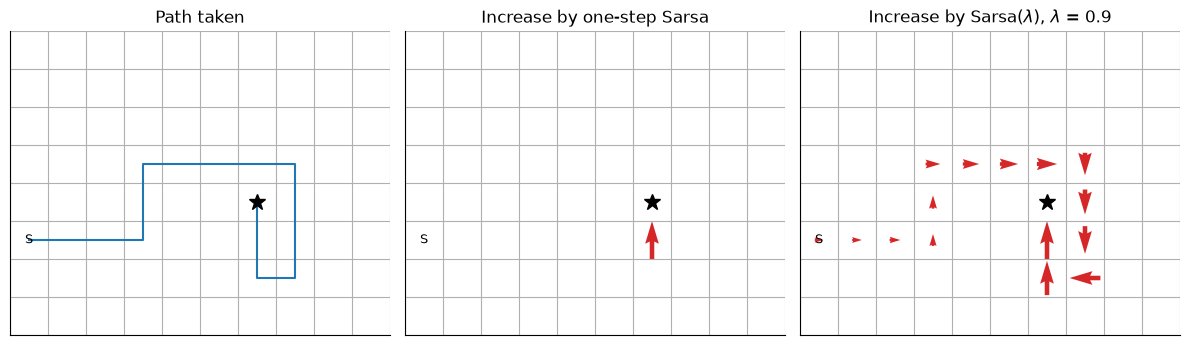

Pairs strengthened by one-step Sarsa: 1 ; by Sarsa(lambda): 15
Rise of the pair k steps before the reward, k = 0, 1, 2, ..., 14: [0.5, 0.45, 0.405, 0.3645, 0.3281, 0.2952, 0.2657, 0.2391, 0.2152, 0.1937, 0.1743, 0.1569, 0.1412, 0.1271, 0.1144]
Largest gap to alpha (gamma lambda)^k for accumulating, replacing and box-dutch traces: 5.6e-17; one-step rise of the last pair: 0.5
Dutch traces by the chapter's equation: rise of the first move 7.0e-06; gap to alpha ((1 - alpha) gamma lambda)^k: 3.5e-18
Checkpoint: one-step Sarsa strengthens one pair, Sarsa(lambda) all 15, with strength alpha (gamma lambda)^k


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
draw_grid(axes[0], trace_world, np.zeros_like(zeros), "Path taken", trace_path)
draw_grid(axes[1], trace_world, increase["one-step Sarsa"], "Increase by one-step Sarsa")
draw_grid(axes[2], trace_world, increase["Sarsa(lambda), replacing"], f"Increase by Sarsa($\\lambda$), $\\lambda$ = {LAMBDA_PATH}")
plt.tight_layout()
plt.show()
rises = [increase["Sarsa(lambda), replacing"][pair] for pair in reversed(trace_path)]
print("Pairs strengthened by one-step Sarsa:", int((increase["one-step Sarsa"] > 0).sum()), "; by Sarsa(lambda):", int((increase["Sarsa(lambda), replacing"] > 0).sum()))
print("Rise of the pair k steps before the reward, k = 0, 1, 2, ..., 14:", np.round(rises, 4).tolist())
trace_error = max(np.abs(increase[f"Sarsa(lambda), {kind}"] - expected).max() for kind in ("accumulating", "replacing", "dutch"))
dutch_equation_error = np.abs(increase["Sarsa(lambda), dutch_equation"] - expected_dutch_equation).max()
print(f"Largest gap to alpha (gamma lambda)^k for accumulating, replacing and box-dutch traces: {trace_error:.1e}; one-step rise of the last pair: {increase['one-step Sarsa'][trace_path[-1]]}")
print(
    f"Dutch traces by the chapter's equation: rise of the first move {increase['Sarsa(lambda), dutch_equation'][trace_path[0]]:.1e}; "
    f"gap to alpha ((1 - alpha) gamma lambda)^k: {dutch_equation_error:.1e}"
)
print("Checkpoint: one-step Sarsa strengthens one pair, Sarsa(lambda) all 15, with strength alpha (gamma lambda)^k")

### Reading the result

- The left panel is the path (S marks the start, the star the goal). The middle panel shows one arrow, the last move, of full length. The right panel shows an arrow for every one of the 15 moves, shrinking with the distance from the reward, as in the book's figure (compared by eye).
- The counts confirm it: one-step Sarsa strengthens 1 pair and Sarsa($\lambda$) 15. The rise of the pair $k$ steps before the reward starts at 0.5 for $k = 0$ and falls by the factor 0.9 per step to 0.1144 for $k = 14$, the first move.
- The rises equal $\alpha (\gamma\lambda)^k$ with a largest gap of 5.6e-17 for accumulating, replacing and box-dutch traces; the book's fall-off of 0.9 per step is $\gamma\lambda$. Equation-dutch traces give $\alpha((1-\alpha)\gamma\lambda)^k$ with a gap of 3.5e-18, a fall-off of 0.45 per step; the book's figure is described with 0.9 per step, so it matches the other three types.
- The grid, the path and $\alpha$ are our choices (the book prints no step size and its path differs), so only the shape of the result is compared with the book.

## 4. Sarsa($\lambda$) on the windy gridworld

The performance comparison uses the windy gridworld of the first section with the settings the previous chapter gives for Sarsa: $\varepsilon = 0.1$, $\alpha = 0.5$, $Q = 0$ initially. The measure is the number of steps per episode, averaged over an agent's first 100 episodes; fewer steps mean faster learning.

Terms used from here on:
- **Standard error** of a mean over runs: the sample standard deviation of the per-run values divided by the square root of the number of runs. A difference smaller than about two standard errors is not treated as a finding.
- **Run-matched change**: for two methods, the mean over runs of the difference between run $i$ of one and run $i$ of the other, with the standard error of those differences. All methods in a comparison get the same random numbers at the same global step, but their trajectories diverge as soon as the methods choose differently, so the matching is weak (it barely shrinks the standard error) and no more is claimed for it.
- **Greedy policy optimal**: the share of runs whose final greedy policy, followed from the start, reaches the goal in exactly the optimal 15 steps.

Where the toy differs from the book:
- The book shows one run of 8000 time steps (about 170 episodes) as cumulative time against episodes. Here there are 100 independent runs of 100 episodes each, stepped in lockstep as arrays, and the per-run mean steps per episode is reported.
- The chapter does not say which trace type to use here; replacing traces are used. The end of this section compares the trace types.
- An episode still running after 5000 steps is stopped there (counted as 5000 steps, traces cleared) and restarted from the start with the current $Q$, which changes the dynamics of that run: a diverged $Q$ carries over. Only runs that diverge are affected, and the tables count the capped episodes among the recorded ones.
- The lockstep loop draws, per global step and for all runs, one uniform number for the exploration test, one random action and four uniform keys for tie-breaking, in that order.
- The value 0.8, compared with 0.9 below, was chosen after seeing that it came close in the sweep (post hoc), so that comparison is descriptive.

In [13]:
class Run(NamedTuple):
    """Result of `run_control`: steps per episode `[run, episode]`, final action values `[run, s, a]`, the number of non-greedy next actions,
    the number of steps counted, the largest trace seen and the number of episodes stopped at the step cap."""

    steps: np.ndarray
    Q: np.ndarray
    n_cut: int
    n_counted: int
    max_trace: float
    n_capped: int

In [14]:
def run_control(w: World, method: str, kind: str, lam: float, alpha: float, eps: float, n_runs: int, n_episodes: int, seq: np.random.SeedSequence, gamma: float = GAMMA) -> Run:
    """Epsilon-greedy Sarsa(lambda) or Watkins's Q(lambda) on `n_runs` independent copies of the task, stepped in lockstep until each has finished `n_episodes` episodes.

    Q starts at 0; ties are broken uniformly at random. An episode still running after `MAX_EPISODE_STEPS` steps is stopped there (counted with that length,
    traces cleared, Q kept, which changes the dynamics of that run) so that one diverging run cannot stall the lockstep loop. `n_capped`, `n_cut`, `n_counted` and `max_trace`
    cover only steps taken while a run has fewer than `n_episodes` finished episodes, i.e. the recorded data. Draw order per global step: u[n_runs], a_random[n_runs], tie[n_runs, 4],
    from one generator built from `seq`, so methods given the same `seq` see the same draws at the same step.
    """
    rng = np.random.default_rng(seq)
    idx = np.arange(n_runs)
    Q = np.zeros((n_runs, len(w.next_state), 4))
    E, steps = np.zeros_like(Q), np.zeros((n_runs, n_episodes), int)
    done_count, length = np.zeros(n_runs, int), np.zeros(n_runs, int)
    n_cut = n_counted = n_capped = 0
    max_trace = 0.0
    s = np.full(n_runs, w.start)

    def draws() -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        return rng.random(n_runs), rng.integers(0, 4, n_runs), rng.random((n_runs, 4))

    a = epsilon_greedy(Q[idx, s], eps, *draws())
    while done_count.min() < n_episodes:
        u, a_random, tie = draws()
        s2, r = w.next_state[s, a], w.reward[s, a]
        a2 = epsilon_greedy(Q[idx, s2], eps, u, a_random, tie)
        greedy2, e_new = trace_step(Q, E, idx, s, a, r, s2, a2, method, kind, alpha, gamma, lam)
        length += 1
        recording = done_count < n_episodes
        done = s2 == w.goal
        capped = ~done & (length >= MAX_EPISODE_STEPS)
        n_capped += int((capped & recording).sum())
        n_cut, n_counted = n_cut + int((~greedy2 & ~done & recording).sum()), n_counted + int((~done & recording).sum())
        max_trace = max(max_trace, float(e_new[recording].max()))
        ended = done | capped
        for i in np.flatnonzero(ended & (done_count < n_episodes)):
            steps[i, done_count[i]] = length[i]
        done_count += ended
        length[ended], E[ended] = 0, 0.0
        s = np.where(ended, w.start, s2)
        a = np.where(ended, epsilon_greedy(Q[idx, s], eps, u, a_random, tie), a2)
    return Run(steps, Q, n_cut, n_counted, max_trace, n_capped)

In [15]:
def mean_se(x: np.ndarray) -> tuple[float, float]:
    """Mean and standard error of the mean (sample standard deviation over the square root of the count)."""
    return float(x.mean()), float(x.std(ddof=1) / np.sqrt(len(x)))


def ratio_of_means(x: np.ndarray, y: np.ndarray) -> tuple[float, float]:
    """Ratio of the mean of `x` to the mean of `y` with its standard error by the delta method, treating the two sets of runs as independent."""
    (mx, sx), (my, sy) = mean_se(x), mean_se(y)
    return mx / my, mx / my * float(np.hypot(sx / mx, sy / my))


def speed(run: Run, last: int | None = None) -> np.ndarray:
    """Steps per episode of each run, averaged over all its episodes or over its last `last` ones."""
    return run.steps[:, -last:].mean(1) if last else run.steps.mean(1)


def last_means(run: Run) -> tuple[float, float]:
    """Mean and standard error of the steps per episode over the final window of episodes."""
    return mean_se(speed(run, N_LAST))


def greedy_steps(w: World, Q: np.ndarray, cap: int = GREEDY_CAP) -> np.ndarray:
    """Steps from the start to the goal when each run follows its own greedy policy (first maximizer on ties); `cap + 1` where the goal is not reached within `cap` steps."""
    idx, s, steps = np.arange(len(Q)), np.full(len(Q), w.start), np.full(len(Q), cap + 1)
    for t in range(1, cap + 1):
        s = w.next_state[s, Q[idx, s].argmax(-1)]
        steps[(s == w.goal) & (steps > cap)] = t
    return steps

In [16]:
seq_sweep, seq_types = np.random.SeedSequence(SEED_WINDY).spawn(2)
sweep = {lam: run_control(windy, "sarsa", "replacing", lam, ALPHA, EPS, N_RUNS, N_EPISODES, seq_sweep) for lam in LAMBDAS}
exact_soft = V_soft[windy.start]
print(
    f"Replacing traces, alpha = {ALPHA}, epsilon = {EPS}, {N_RUNS} runs of {N_EPISODES} episodes; every method gets the same random draws at the same global step. Standard errors are over runs; "
    f"a run-matched change is the mean of the differences between run i of the two methods (matching by run index is a weak pairing)."
)
print(f"{'lambda':>6} {'steps/episode':>15} {'run-matched change vs 0':>20} {'last ' + str(N_LAST) + ' episodes':>18} {'capped':>7} {'greedy policy optimal':>22}")
for lam, run in sweep.items():
    m, se = mean_se(speed(run))
    d, d_se = mean_se(speed(run) - speed(sweep[0.0]))
    last, last_se = mean_se(speed(run, N_LAST))
    print(f"{lam:>6} {m:>9.2f} ±{se:.2f} {d:>+13.2f} ±{d_se:.2f} {last:>10.2f} ±{last_se:.2f} {run.n_capped:>7} {(greedy_steps(windy, run.Q) == OPTIMAL_STEPS).mean():>22.0%}")
best_pair = mean_se(speed(sweep[LAMBDA]) - speed(sweep[LAMBDA_NEAR_BEST]))
print(f"Run-matched change, lambda {LAMBDA} minus {LAMBDA_NEAR_BEST}: {best_pair[0]:+.2f} ±{best_pair[1]:.2f}")
print(f"Exact best epsilon-greedy-class length at epsilon = {EPS}: {-exact_soft:.3f}; shortest episode seen anywhere: {min(run.steps.min() for run in sweep.values())}")

Replacing traces, alpha = 0.5, epsilon = 0.1, 100 runs of 100 episodes; every method gets the same random draws at the same global step. Standard errors are over runs; a run-matched change is the mean of the differences between run i of the two methods (matching by run index is a weak pairing).
lambda   steps/episode run-matched change vs 0   last 20 episodes  capped  greedy policy optimal
   0.0     65.43 ±0.18         +0.00 ±0.00      29.57 ±0.27       0                    11%
   0.3     55.98 ±0.20         -9.45 ±0.27      26.47 ±0.31       0                    27%
   0.6     46.21 ±0.21        -19.22 ±0.28      23.81 ±0.49       0                    20%
   0.8     40.98 ±0.25        -24.45 ±0.31      23.07 ±0.58       0                     7%
   0.9     41.50 ±0.28        -23.93 ±0.33      25.84 ±0.78       0                     4%
  0.95     46.32 ±0.48        -19.11 ±0.50      30.89 ±1.14       0                     0%
  0.99     73.69 ±1.49         +8.26 ±1.50      51.27 ±3.89  

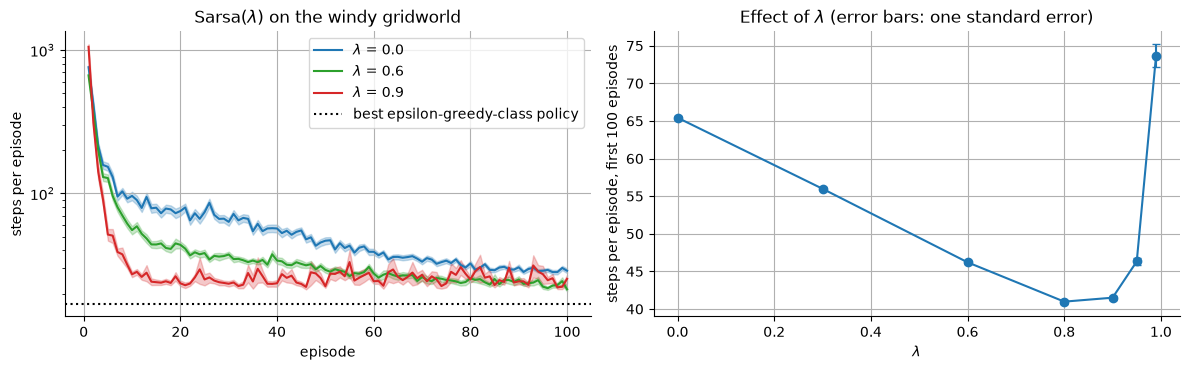

Mean steps at episodes 5, 10 and 20 for the plotted lambdas: {0.0: [153.3, 96.1, 75.3], 0.6: [127.9, 55.5, 43.8], 0.9: [51.6, 27.3, 23.6]}
Checkpoint: Sarsa(lambda) learns faster than one-step Sarsa for intermediate lambda, and every episode takes at least the optimal 15 steps


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lam, color in zip(LAMBDAS_PLOTTED, ("C0", "C2", "C3")):
    mean = sweep[lam].steps.mean(0)
    axes[0].plot(np.arange(1, N_EPISODES + 1), mean, color=color, label=f"$\\lambda$ = {lam}")
    axes[0].fill_between(np.arange(1, N_EPISODES + 1), mean - sweep[lam].steps.std(0, ddof=1) / np.sqrt(N_RUNS), mean + sweep[lam].steps.std(0, ddof=1) / np.sqrt(N_RUNS), color=color, alpha=0.25)
axes[0].axhline(-exact_soft, color="k", ls=":", label="best epsilon-greedy-class policy")
axes[0].set(yscale="log", xlabel="episode", ylabel="steps per episode", title="Sarsa($\\lambda$) on the windy gridworld")
axes[0].legend()
ses = [mean_se(speed(run)) for run in sweep.values()]
axes[1].errorbar(LAMBDAS, [m for m, _ in ses], yerr=[se for _, se in ses], marker="o", capsize=3)
axes[1].set(xlabel="$\\lambda$", ylabel=f"steps per episode, first {N_EPISODES} episodes", title="Effect of $\\lambda$ (error bars: one standard error)")
plt.tight_layout()
plt.show()
print("Mean steps at episodes 5, 10 and 20 for the plotted lambdas:", {lam: [round(float(sweep[lam].steps[:, e - 1].mean()), 1) for e in (5, 10, 20)] for lam in LAMBDAS_PLOTTED})
print("Checkpoint: Sarsa(lambda) learns faster than one-step Sarsa for intermediate lambda, and every episode takes at least the optimal 15 steps")

### Reading the result

- Traces speed learning up, and an intermediate $\lambda$ is best. Steps per episode over the first 100 episodes fall from 65.43 for $\lambda = 0$ (one-step Sarsa) to 55.98 ($\lambda = 0.3$), 46.21 (0.6), 40.98 (0.8) and 41.50 (0.9); every run-matched change from $\lambda = 0$ for these is below $-9$ with a standard error of at most 0.33. The run-matched change from 0.8 to 0.9 is +0.52 with standard error 0.36, which is not a finding. $\lambda = 0.95$ gives 46.32, about 5 steps above the best.
- $\lambda = 0.99$, nearly Monte Carlo (the method that waits for the complete return and does not bootstrap), is slower than one-step Sarsa: 73.69, a change of +8.26 with standard error 1.50, and 3 recorded episodes were stopped at the step cap. This agrees with the chapter: traces so long that the method is nearly Monte Carlo degrade performance sharply, and an intermediate mixture is best.
- Averaged over the last 20 episodes the means are 29.57 for $\lambda = 0$, 23.81 (0.6), 23.07 (0.8), 25.84 (0.9), 30.89 (0.95) and 51.27 (0.99), with standard errors 0.27, 0.49, 0.58, 0.78, 1.14 and 3.89: late in the run 0.6 and 0.8 are not distinguishable, and 0.9 has a higher mean. All stay above the exact floor of 17.048 (dotted line in the left panel), because 100 episodes with $\varepsilon = 0.1$ do not reach it. The book's figure of about 17 comes from a longer run, which was not repeated here.
- The share of runs whose greedy policy is exactly optimal is low everywhere: 11%, 27%, 20%, 7%, 4%, 0% and 0% for the seven values of $\lambda$ in order. With 100 runs a share has a standard error of up to 5 points, so differences of a few points are noise. Episodes get short without the greedy policy being exactly optimal in most runs.
- The mean steps at episodes 5, 10 and 20 are 153.3, 96.1 and 75.3 for $\lambda = 0$, 127.9, 55.5 and 43.8 for 0.6, and 51.6, 27.3 and 23.6 for 0.9: the $\lambda = 0.9$ curve (red in the left panel, log scale) falls first. The right panel shows the U-shape of the steps against $\lambda$, by eye.

### Trace types

Sarsa($\lambda$) with $\lambda = 0.9$ and the four trace types (accumulating, replacing, box-dutch and equation-dutch), against one-step Sarsa, 100 runs of 40 episodes each. The geometric series gives bounds that the largest trace seen must respect: 1 for replacing traces, $1 / (1 - (1-\alpha)\gamma\lambda) = 1.818$ for both dutch variants and $1 / (1 - \gamma\lambda) = 10$ for accumulating traces, reached by a pair repeated step after step.

Accumulating traces turn out heavy-tailed, so besides means the cell reports the median of the per-run differences from replacing traces, the number of runs in which accumulating is slower, and a two-sided sign test (under the hypothesis that either is equally likely to be slower, the number of runs in which accumulating is slower is binomial with probability one half). The sign test is held to the family-wise limit of the checkpoints below.

In [18]:
types = {"one-step Sarsa": ("replacing", 0.0), **{f"Sarsa({LAMBDA}), {kind}": (kind, LAMBDA) for kind in ("replacing", "dutch", "dutch_equation", "accumulating")}}
type_runs = {name: run_control(windy, "sarsa", kind, lam, ALPHA, EPS, N_RUNS_TYPES, N_EPISODES_TYPES, seq_types) for name, (kind, lam) in types.items()}
print(f"{N_RUNS_TYPES} runs of {N_EPISODES_TYPES} episodes, alpha = {ALPHA}")
for name, run in type_runs.items():
    m, se = mean_se(speed(run))
    d, d_se = mean_se(speed(run) - speed(type_runs["one-step Sarsa"]))
    print(
        f"{name:>26}: steps/episode {m:8.2f} ±{se:5.2f}; run-matched change vs one-step {d:+8.2f} ±{d_se:5.2f}; "
        f"longest episode {run.steps.max():6d} (capped: {run.n_capped}); largest trace {run.max_trace:6.2f}"
    )
dutch_diff = mean_se(speed(type_runs[f"Sarsa({LAMBDA}), dutch_equation"]) - speed(type_runs[f"Sarsa({LAMBDA}), dutch"]))
print(f"Run-matched change, equation-dutch minus box-dutch: {dutch_diff[0]:+.2f} ±{dutch_diff[1]:.2f}")
acc_diff = speed(type_runs[f"Sarsa({LAMBDA}), accumulating"]) - speed(type_runs[f"Sarsa({LAMBDA}), replacing"])
acc_slower = int((acc_diff > 0).sum())
sign_p = min(1.0, 2 * sum(comb(N_RUNS_TYPES, k) for k in range(max(acc_slower, N_RUNS_TYPES - acc_slower), N_RUNS_TYPES + 1)) / 2**N_RUNS_TYPES)
print(
    f"Accumulating minus replacing, per run: median {np.median(acc_diff):+.2f}; accumulating slower in {acc_slower} of {N_RUNS_TYPES} runs (two-sided sign test p = {sign_p:.1e}); "
    f"mean {acc_diff.mean():+.2f} ±{acc_diff.std(ddof=1) / np.sqrt(N_RUNS_TYPES):.2f}"
)
print("Per-run mean steps per episode of the five slowest accumulating runs:", np.round(np.sort(speed(type_runs[f"Sarsa({LAMBDA}), accumulating"]))[::-1][:5], 0).tolist())
print("Checkpoint: replacing and dutch traces help at alpha = 0.5; accumulating traces do not clearly help")

100 runs of 40 episodes, alpha = 0.5
            one-step Sarsa: steps/episode   108.38 ± 0.49; run-matched change vs one-step    +0.00 ± 0.00; longest episode   1327 (capped: 0); largest trace   1.00
     Sarsa(0.9), replacing: steps/episode    63.46 ± 0.70; run-matched change vs one-step   -44.93 ± 0.93; longest episode   1686 (capped: 0); largest trace   1.00
         Sarsa(0.9), dutch: steps/episode    64.36 ± 0.80; run-matched change vs one-step   -44.02 ± 0.92; longest episode   1879 (capped: 0); largest trace   1.82
Sarsa(0.9), dutch_equation: steps/episode    80.42 ± 0.41; run-matched change vs one-step   -27.96 ± 0.64; longest episode   1179 (capped: 0); largest trace   1.82
  Sarsa(0.9), accumulating: steps/episode   122.47 ±27.44; run-matched change vs one-step   +14.09 ±27.43; longest episode   5000 (capped: 28); largest trace  10.00
Run-matched change, equation-dutch minus box-dutch: +16.06 ±0.93
Accumulating minus replacing, per run: median +15.91; accumulating slower in 

### Reading the trace types

- Replacing and box-dutch traces behave alike: 63.46 and 64.36 steps per episode (standard errors 0.70 and 0.80), against 108.38 for one-step Sarsa, changes of $-44.93$ and $-44.02$ with standard errors 0.93 and 0.92.
- The choice between the box and the equation for dutch traces matters here. Equation-dutch traces, which fall off by $(1-\alpha)\gamma\lambda = 0.45$ per step instead of 0.9, give 80.42 steps per episode (standard error 0.41), a change of $-27.96$ from one-step Sarsa but +16.06 with standard error 0.93 from box-dutch. Everywhere else in the notebook, dutch means the box version, as in the printed algorithm. Explanation, not tested: the faster fall-off shortens the effective trace, as a smaller $\lambda$ would.
- Accumulating traces are erratic: 122.47 with a standard error of 27.44 and a change of +14.09 ± 27.43 against one-step Sarsa, so the mean difference is not distinguishable from zero. Five runs diverge (per-run means 2665, 984, 320, 259 and 168 steps per episode for the five slowest), 28 recorded episodes were stopped at the cap, and none of the other methods had any. Against replacing traces the mean difference is +59.02 ± 27.46, dominated by those runs; the robust summary is a median difference of +15.91, accumulating being slower in 86 of 100 runs (sign test $p$ = 8.3e-14). The finding is moderate: accumulating traces are slower than replacing traces in most runs at $\alpha = 0.5$, by a median of about 16 steps per episode, and a few runs diverge. Because of the cap, the means are lower bounds.
- The largest traces are 1.00 (replacing), 1.82 (both dutch variants) and 10.00 (accumulating), matching the limits above: accumulating traces do grow to 10 here. Explanation, not tested: with $\alpha = 0.5$ a trace above 2 makes the update $\alpha \delta E$ overshoot the TD error, which is unstable.
- The book gives no windy-gridworld comparison of trace types, so none is checked against it.

## 5. Watkins's Q($\lambda$)

Q-learning is off-policy: it learns the values of one policy (the greedy one) from data generated by another (an exploring one), so its target uses the greedy next action whatever action was taken. A multi-step return from $(S_t, A_t)$ is therefore valid for the greedy policy only while the agent acts greedily. **Watkins's Q($\lambda$)** keeps the traces of Sarsa($\lambda$), except that all traces are set to 0 after an exploratory action:

$$
\delta = R + \gamma \max_a Q(S', a) - Q(S, A), \qquad
E \leftarrow \gamma\lambda E \;\text{ if } A' = A^*, \quad E \leftarrow 0 \;\text{ otherwise}
$$

where $A^*$ is a greedy action in $S'$ (and $A^* = A'$ if $A'$ ties for the maximum). The trace increment and the update of $Q$ are as in Sarsa($\lambda$). With $\lambda = 0$ this is one-step Q-learning.

The chapter also gives the same method as an equation, $E_t = \gamma\lambda E_{t-1} + I_{sS_t} I_{aA_t}$ if $Q_{t-1}(S_t, A_t) = \max_a Q_{t-1}(S_t, a)$ and $E_t = I_{sS_t} I_{aA_t}$ otherwise, with $I$ the identity indicator (1 if the pair is the visited one, else 0). The box tests $A'$ at step $t$ against the values before step $t$'s update; the equation tests $A_{t+1}$ against $Q_t$, the same values. They agree exactly, and differ only if greediness is judged against the already-updated $Q$.

`watkins_by_equation` writes the equation directly, with its own loop and no shared code with `trace_step`. Comparing it with the box is a consistency check of two code paths; the independent anchor is the hand-computed traces of the Sarsa($\lambda$) section. The comparison runs on the chapter's four-step episode and on 300 random trajectories (a different set from the earlier check) with all three trace types. A third check tests the tie rule by hand: with all values 0 every next action ties for the maximum and counts as greedy, so no trace is ever cut and Watkins's traces must equal Sarsa($\lambda$)'s.

In [19]:
def watkins_by_equation(
    w: World, path: list[tuple[int, int]], Q0: np.ndarray, kind: str, alpha: float, gamma: float, lam: float, test_after_update: bool = False
) -> tuple[list[np.ndarray], np.ndarray]:
    """Watkins's Q(lambda) written as the chapter's equations: E_t = gamma lambda E_{t-1} + I if Q_{t-1}(S_t, A_t) is the maximum over actions, else I; Q_{t+1} = Q_t + alpha delta_t E_t.

    Returns the traces right after each increment and the final action values. `test_after_update` tests greediness against Q_t instead of Q_{t-1}.
    """
    Q, Q_prev, E, log = Q0.copy(), Q0.copy(), np.zeros_like(Q0), []
    for s, a in path:
        basis = Q if test_after_update else Q_prev
        E = gamma * lam * E if basis[s, a] == basis[s].max() else np.zeros_like(E)
        E[s, a] = 1.0 if kind == "replacing" else ((1 - alpha) * E[s, a] + 1 if kind == "dutch" else E[s, a] + 1)
        log.append(E.copy())
        delta = w.reward[s, a] + gamma * Q[w.next_state[s, a]].max() - Q[s, a]
        Q_prev, Q = Q, Q + alpha * delta * E
    return log, Q

In [20]:
log_box: list = []
replay(dataset, dataset_path, "watkins", "accumulating", DATASET_ALPHA, GAMMA, DATASET_LAMBDA, dataset_Q0, log_box)
log_eq, Q_eq = watkins_by_equation(dataset, dataset_path, dataset_Q0, "accumulating", DATASET_ALPHA, GAMMA, DATASET_LAMBDA)
dataset_gap = max(np.abs(log_box[t][0] - log_eq[t]).max() for t in range(4))
print(f"Hand-made four-step trajectory: largest gap between the box's traces and the equation's traces {dataset_gap:.1e}")
log_tie: list = []
replay(dataset, dataset_path, "watkins", "accumulating", DATASET_ALPHA, GAMMA, DATASET_LAMBDA, np.zeros_like(dataset_Q0), log_tie)
tie_gap = max(np.abs(log_tie[t][0] - dense(hand_E["sarsa"][t], (5, 2))).max() for t in range(4))
print(f"All values 0, so every next action ties for the maximum and counts as greedy: Watkins's traces equal Sarsa's, largest gap {tie_gap:.1e}")

Hand-made four-step trajectory: largest gap between the box's traces and the equation's traces 0.0e+00
All values 0, so every next action ties for the maximum and counts as greedy: Watkins's traces equal Sarsa's, largest gap 0.0e+00


In [21]:
rng_q, rng_path = (np.random.default_rng(seq) for seq in np.random.SeedSequence(SEED_EQUIV).spawn(2))
box_gap, differs_after = 0.0, 0
for _ in range(N_PATHS):
    path, Q0 = random_path(random_world, rng_path), np.round(rng_q.random((RANDOM_GRID**2, 4)), 1)
    for kind in ("accumulating", "dutch", "replacing"):
        log_box = []
        Q_box = replay(random_world, path, "watkins", kind, PATH_ALPHA, PATH_GAMMA, PATH_LAMBDA, Q0, log_box)
        log_eq, Q_eq = watkins_by_equation(random_world, path, Q0, kind, PATH_ALPHA, PATH_GAMMA, PATH_LAMBDA)
        box_gap = max(box_gap, np.abs(Q_box - Q_eq).max(), max(np.abs(b[0] - e).max() for b, e in zip(log_box, log_eq)))
        differs_after += np.abs(watkins_by_equation(random_world, path, Q0, kind, PATH_ALPHA, PATH_GAMMA, PATH_LAMBDA, True)[1] - Q_eq).max() > EXACT_TOL
print(f"{N_PATHS} random trajectories, three trace types: largest gap between the pseudocode and the equation {box_gap:.1e}")
print(f"Demonstration: testing greediness against the updated Q instead of Q before the update changes the final Q in {differs_after} of {3 * N_PATHS} runs")
print("Checkpoint: the pseudocode's A' = A* test and the equation give the same traces; they differ only if greediness is judged after the update")

300 random trajectories, three trace types: largest gap between the pseudocode and the equation 0.0e+00
Demonstration: testing greediness against the updated Q instead of Q before the update changes the final Q in 129 of 900 runs
Checkpoint: the pseudocode's A' = A* test and the equation give the same traces; they differ only if greediness is judged after the update


### Reading the result

- On the four-step episode the box and the equation give the same traces and values, largest gap 0.
- On 300 random trajectories with all three trace types the largest gap between them is also 0.
- With all values 0 Watkins's traces equal Sarsa($\lambda$)'s with a gap of 0, so a tie counts as greedy as the box says.
- Judging greediness against the updated $Q$ instead changes the final $Q$ in 129 of the 900 runs. The equation's subscript $t-1$, the values before the update, therefore matters, and it is what the box does.

### Watkins's Q($\lambda$) on the windy gridworld

Four methods on the same task and settings as the previous section (replacing traces, $\lambda = 0.9$): one-step Sarsa, one-step Q-learning (Watkins's method with $\lambda = 0$), Sarsa(0.9) and Watkins's Q(0.9). They share one seeded stream, separate from the previous section's, so the comparison is within this cell. Note that Watkins's Q(0.9) and Sarsa(0.9) use different targets (the greedy next action's value against the value of the next action taken), so their difference does not isolate the effect of cutting traces.

The share of steps followed by a non-greedy action is also measured. As derived in the first section, at every step this has probability at most $\frac{3}{4}\varepsilon$. By Hoeffding's inequality, which bounds how far a sum of bounded variables with conditional mean at most $p$ can exceed $np$, the measured share over $n$ recorded steps stays below $\frac{3}{4}\varepsilon + \sqrt{\ln(1/\delta)/(2n)}$ except with probability $\delta = 10^{-6}$.

The printed lines about the learning curves (mean steps at episodes 10 and 20 and the spread of the mean curve over episodes 21 to 100, which includes any downward trend) back the statements about the plot.

In [22]:
def mean_se_text(x: np.ndarray) -> str:
    """'mean ± standard error' with two decimals."""
    m, se = mean_se(x)
    return f"{m:7.2f} ±{se:5.2f}"


seq_watkins = np.random.SeedSequence(SEED_WATKINS)
compared = {
    name: run_control(windy, method, "replacing", lam, ALPHA, EPS, N_RUNS, N_EPISODES, seq_watkins)
    for name, method, lam in (("one-step Sarsa", "sarsa", 0.0), ("Q-learning (lambda = 0)", "watkins", 0.0), (f"Sarsa({LAMBDA})", "sarsa", LAMBDA), (f"Watkins's Q({LAMBDA})", "watkins", LAMBDA))
}
one_step_sarsa, qlearning, sarsa_lambda, watkins = compared.values()
print(f"{N_RUNS} runs of {N_EPISODES} episodes, epsilon = {EPS}, alpha = {ALPHA}, replacing traces")
print(f"{'method':>24} {'steps/episode':>17} {'last ' + str(N_LAST):>15} {'greedy policy optimal':>22}")
for name, run in compared.items():
    print(f"{name:>24} {mean_se_text(speed(run))} {mean_se_text(speed(run, N_LAST))} {(greedy_steps(windy, run.Q) == OPTIMAL_STEPS).mean():>22.0%}")
for name, a, b in (
    (f"Watkins's Q({LAMBDA}) minus Q-learning", watkins, qlearning),
    (f"Watkins's Q({LAMBDA}) minus Sarsa({LAMBDA})", watkins, sarsa_lambda),
    ("Q-learning minus one-step Sarsa", qlearning, one_step_sarsa),
):
    print(f"run-matched change in steps/episode, {name}: {mean_se_text(speed(a) - speed(b))}")
cut_share = watkins.n_cut / watkins.n_counted
cut_limit = 0.75 * EPS + np.sqrt(np.log(1 / CUT_DELTA) / (2 * watkins.n_counted))
print(f"Share of steps followed by a non-greedy action: {cut_share:.4f} (one cut per {1 / cut_share:.1f} steps); limit 3/4 epsilon + Hoeffding allowance = {cut_limit:.4f}")

100 runs of 100 episodes, epsilon = 0.1, alpha = 0.5, replacing traces
                  method     steps/episode         last 20  greedy policy optimal
          one-step Sarsa   65.25 ± 0.19   30.64 ± 0.35                     7%
 Q-learning (lambda = 0)   61.49 ± 0.04   26.49 ± 0.12                    13%
              Sarsa(0.9)   41.17 ± 0.29   23.99 ± 0.55                     4%
        Watkins's Q(0.9)   38.32 ± 0.43   19.36 ± 0.16                    30%
run-matched change in steps/episode, Watkins's Q(0.9) minus Q-learning:  -23.17 ± 0.44
run-matched change in steps/episode, Watkins's Q(0.9) minus Sarsa(0.9):   -2.85 ± 0.51
run-matched change in steps/episode, Q-learning minus one-step Sarsa:   -3.76 ± 0.19
Share of steps followed by a non-greedy action: 0.0728 (one cut per 13.7 steps); limit 3/4 epsilon + Hoeffding allowance = 0.0793


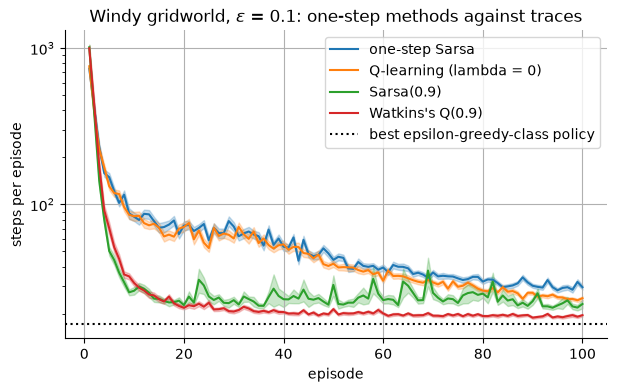

          one-step Sarsa: mean steps at episode 10   83.4, at episode 20  73.2; episodes 21-100: mean 44.46, episode-to-episode standard deviation of the mean curve 14.35
 Q-learning (lambda = 0): mean steps at episode 10   84.0, at episode 20  71.8; episodes 21-100: mean 40.66, episode-to-episode standard deviation of the mean curve 14.32
              Sarsa(0.9): mean steps at episode 10   28.0, at episode 20  22.7; episodes 21-100: mean 25.35, episode-to-episode standard deviation of the mean curve 2.91
        Watkins's Q(0.9): mean steps at episode 10   31.4, at episode 20  21.8; episodes 21-100: mean 20.16, episode-to-episode standard deviation of the mean curve 0.98
Checkpoint: Watkins's Q(lambda) beats one-step Q-learning, and the share of cut steps stays below its derived limit


In [23]:
fig, ax = plt.subplots()
for (name, run), color in zip(compared.items(), ("C0", "C1", "C2", "C3")):
    mean, se = run.steps.mean(0), run.steps.std(0, ddof=1) / np.sqrt(N_RUNS)
    ax.plot(np.arange(1, N_EPISODES + 1), mean, color=color, label=name)
    ax.fill_between(np.arange(1, N_EPISODES + 1), mean - se, mean + se, color=color, alpha=0.25)
ax.axhline(-exact_soft, color="k", ls=":", label="best epsilon-greedy-class policy")
ax.set(yscale="log", xlabel="episode", ylabel="steps per episode", title=f"Windy gridworld, $\\epsilon$ = {EPS}: one-step methods against traces")
ax.legend()
plt.show()
for name, run in compared.items():
    tail = run.steps[:, 20:].mean(0)
    print(
        f"{name:>24}: mean steps at episode 10 {run.steps[:, 9].mean():6.1f}, at episode 20 {run.steps[:, 19].mean():5.1f}; "
        f"episodes 21-{N_EPISODES}: mean {tail.mean():5.2f}, episode-to-episode standard deviation of the mean curve {tail.std(ddof=1):4.2f}"
    )
print("Checkpoint: Watkins's Q(lambda) beats one-step Q-learning, and the share of cut steps stays below its derived limit")

### Reading the result

- At $\varepsilon = 0.1$ traces give a large speed-up to Q-learning: Watkins's Q(0.9) needs 38.32 steps per episode against 61.49 for Q-learning, a run-matched change of $-23.17$ with standard error 0.44. Both are better than one-step Sarsa (65.25); Q-learning is 3.76 steps (standard error 0.19) faster than one-step Sarsa.
- Watkins's Q(0.9) is also 2.85 steps (standard error 0.51) faster than Sarsa(0.9), 41.17. This does not show what the cut costs or gains, because the two methods also use different targets; it only shows that in this setting the cut does not stop Watkins's Q(0.9) from doing at least as well as Sarsa(0.9). Over the last 20 episodes Watkins's Q(0.9) is the lowest of the four at 19.36, still above the floor 17.048. This holds for one setting; why it is faster is not tested.
- Only 7.28% of steps were followed by a non-greedy action, one cut per 13.7 steps on average: just under the 7.5% that $\frac{3}{4}\varepsilon$ gives for a unique maximizer and under the limit of 7.93% with the allowance. A trace is cut about every 14 steps, longer than the scale $1/(1-\gamma\lambda) = 10$ steps over which it decays anyway; this may be why the cut matters little at $\varepsilon = 0.1$ (explanation, not tested here; the next section varies $\varepsilon$).
- The share of runs whose greedy policy is exactly optimal is 30% for Watkins's Q(0.9), against 13% for Q-learning, 4% for Sarsa(0.9) and 7% for one-step Sarsa (out of 100 runs each, so differences of a few points are noise).
- Q-learning's standard error is only 0.04 against 0.19 to 0.43 for the others, so its runs behave almost alike. Explanation, not tested: with all values starting at 0 and every reward $-1$, unvisited pairs look best and exploration is almost systematic.
- The printed curve values back the plot. By episode 20 the two trace methods are at 22.7 (Sarsa(0.9)) and 21.8 (Watkins) steps, against 73.2 and 71.8 for the one-step methods. Over episodes 21 to 100 Watkins's Q(0.9) has the lowest mean (20.16, against 25.35 for Sarsa(0.9), 40.66 and 44.46), and the smoothest mean curve (episode-to-episode standard deviation 0.98 against 2.91 for Sarsa(0.9); the one-step methods' 14.3 includes their downward trend).

## 6. Frequent exploration cuts the traces

The chapter warns that cutting traces at every exploratory action loses much of the advantage of traces, and that when exploratory actions are frequent, as early in learning, backups longer than one or two steps are rare. To test it, $\varepsilon$ is varied over 0.05, 0.1, 0.2, 0.4 and 0.6 for one-step Q-learning, Watkins's Q(0.9) and, as contrast, Sarsa(0.9), which never cuts. Each $\varepsilon$ has its own seeded stream (spawned from one seed), shared by the three methods at that $\varepsilon$; 100 runs of 100 episodes, replacing traces. A fixed-$\varepsilon$ sweep does not test the chapter's premise that exploration is frequent early in learning and rarer later.

The speed-up is the ratio of the mean steps per episode of Q-learning to that of Watkins's Q(0.9), with a standard error by the delta method that treats the two sets of runs as independent (the runs are not truly paired). The excess speed-up is the ratio minus 1. A cut happens with probability at most $\frac{3}{4}\varepsilon$ per step, so a trace survives $1/(\frac{3}{4}\varepsilon)$ steps or more; to check that exploratory actions are drawn as assumed, the first cell draws 200,000 $\varepsilon$-greedy actions for a state with one clear maximizer and compares the non-greedy share with $\frac{3}{4}\varepsilon$ in standard errors of a binomial share. Four standard errors is the limit for those five comparisons: a false-alarm chance of about $6 \cdot 10^{-5}$ each, about $3 \cdot 10^{-4}$ for any of the five.

The last table column is the exact best $\varepsilon$-greedy-class length from the first section for each $\varepsilon$: a floor that itself rises with $\varepsilon$, so the absolute steps per episode are not comparable across rows.

In [24]:
rng_policy = np.random.default_rng(np.random.SeedSequence(SEED_POLICY))
Q_row = np.tile(Q_ROW, (N_POLICY_DRAWS, 1))  # one unique maximizer, action 0
cut_rates = {}
for eps in EPS_GRID:
    picks = epsilon_greedy(Q_row, eps, rng_policy.random(N_POLICY_DRAWS), rng_policy.integers(0, 4, N_POLICY_DRAWS), rng_policy.random((N_POLICY_DRAWS, 4)))
    p = 0.75 * eps
    cut_rates[eps] = ((picks != 0).mean(), abs((picks != 0).mean() - p) / np.sqrt(p * (1 - p) / N_POLICY_DRAWS))
print(
    "Non-greedy share of epsilon-greedy picks with a unique maximizer (distance from 3/4 epsilon in standard errors):",
    {eps: (round(float(r), 4), round(float(z), 2)) for eps, (r, z) in cut_rates.items()},
)

Non-greedy share of epsilon-greedy picks with a unique maximizer (distance from 3/4 epsilon in standard errors): {0.05: (0.0369, 1.32), 0.1: (0.0755, 0.93), 0.2: (0.1502, 0.29), 0.4: (0.2989, 1.04), 0.6: (0.4492, 0.72)}


In [25]:
seq_eps = dict(zip(EPS_GRID, np.random.SeedSequence(SEED_EPS).spawn(len(EPS_GRID))))
table = {}
for eps in EPS_GRID:
    runs = {
        name: run_control(windy, method, "replacing", lam, ALPHA, eps, N_RUNS, N_EPISODES, seq_eps[eps])
        for name, method, lam in (("Q-learning", "watkins", 0.0), ("Watkins", "watkins", LAMBDA), ("Sarsa", "sarsa", LAMBDA))
    }
    table[eps] = runs
print(f"{N_RUNS} runs of {N_EPISODES} episodes; steps per episode over all episodes, mean ± standard error over runs")
print(
    f"{'epsilon':>8} {'cut share':>10} {'mean run between cuts':>22} {'Q-learning':>16} {f'Watkins Q({LAMBDA})':>16} {f'Sarsa({LAMBDA})':>16}",
    f"{'speed-up of Watkins over Q-learning':>38} {'exact best length':>18}",
)
speedup = {}
for eps, runs in table.items():
    share = runs["Watkins"].n_cut / runs["Watkins"].n_counted
    speedup[eps] = ratio_of_means(speed(runs["Q-learning"]), speed(runs["Watkins"]))
    cells = [mean_se_text(speed(runs[name])) for name in ("Q-learning", "Watkins", "Sarsa")]
    floor = -soft_optimal_values(windy, eps)[0][windy.start]
    print(f"{eps:>8} {share:>10.3f} {1 / share:>22.1f}", *cells, f"{speedup[eps][0]:>30.3f} ±{speedup[eps][1]:.3f} {floor:>18.2f}")

speedup_drop = (speedup[EPS_GRID[0]][0] - speedup[EPS_GRID[-1]][0], np.hypot(speedup[EPS_GRID[0]][1], speedup[EPS_GRID[-1]][1]))
print(f"Speed-up at epsilon = {EPS_GRID[0]} minus at {EPS_GRID[-1]}: {speedup_drop[0]:.3f} ±{speedup_drop[1]:.3f}")
print(
    f"Excess speed-up (ratio minus 1) at epsilon = {EPS_GRID[0]} and {EPS_GRID[-1]}: {speedup[EPS_GRID[0]][0] - 1:.3f} and {speedup[EPS_GRID[-1]][0] - 1:.3f}; "
    f"share lost: {speedup_drop[0] / (speedup[EPS_GRID[0]][0] - 1):.0%}"
)
steps_z = [(speedup[a][0] - speedup[b][0]) / np.hypot(speedup[a][1], speedup[b][1]) for a, b in zip(EPS_GRID[:-1], EPS_GRID[1:])]
print("Drop in the speed-up between neighbouring epsilon values, in combined standard errors:", [round(float(z), 1) for z in steps_z])

100 runs of 100 episodes; steps per episode over all episodes, mean ± standard error over runs
 epsilon  cut share  mean run between cuts       Q-learning   Watkins Q(0.9)       Sarsa(0.9)    speed-up of Watkins over Q-learning  exact best length
    0.05      0.036                   27.8   59.84 ± 0.04   35.97 ± 0.32   36.57 ± 0.32                          1.664 ±0.015              15.96
     0.1      0.071                   14.0   61.50 ± 0.04   38.38 ± 0.37   41.34 ± 0.37                          1.602 ±0.015              17.05
     0.2      0.145                    6.9   65.30 ± 0.06   43.91 ± 0.42   53.93 ± 0.45                          1.487 ±0.014              19.75
     0.4      0.294                    3.4   78.31 ± 0.13   60.28 ± 0.46   91.77 ± 0.75                          1.299 ±0.010              28.94
     0.6      0.442                    2.3  115.52 ± 0.38   96.39 ± 0.57  185.04 ± 1.49                          1.198 ±0.008              53.05
Speed-up at epsilon = 0.05 m

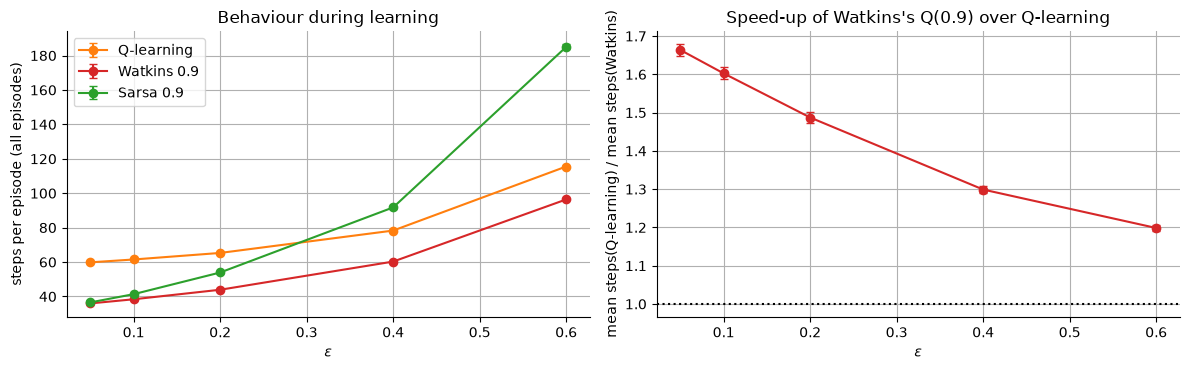

Checkpoint: the speed-up of Watkins's Q(lambda) over Q-learning shrinks as exploration grows


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, color in (("Q-learning", "C1"), ("Watkins", "C3"), ("Sarsa", "C2")):
    ses = [mean_se(speed(table[eps][name])) for eps in EPS_GRID]
    axes[0].errorbar(EPS_GRID, [m for m, _ in ses], yerr=[se for _, se in ses], marker="o", capsize=3, color=color, label=name if name == "Q-learning" else f"{name} {LAMBDA}")
axes[0].set(xlabel="$\\epsilon$", ylabel="steps per episode (all episodes)", title="Behaviour during learning")
axes[0].legend()
ratios = [speedup[eps] for eps in EPS_GRID]
axes[1].errorbar(EPS_GRID, [m for m, _ in ratios], yerr=[se for _, se in ratios], marker="o", capsize=3, color="C3")
axes[1].axhline(1, color="k", ls=":")
axes[1].set(xlabel="$\\epsilon$", ylabel="mean steps(Q-learning) / mean steps(Watkins)", title=f"Speed-up of Watkins's Q({LAMBDA}) over Q-learning")
plt.tight_layout()
plt.show()
print("Checkpoint: the speed-up of Watkins's Q(lambda) over Q-learning shrinks as exploration grows")

### Reading the result

- The drawn actions behave as derived: non-greedy shares 0.0369, 0.0755, 0.1502, 0.2989 and 0.4492 against $\frac{3}{4}\varepsilon$ = 0.0375, 0.075, 0.15, 0.3 and 0.45; the largest distance is 1.32 standard errors.
- The cut share of Watkins's Q(0.9) rises from 0.036 at $\varepsilon = 0.05$ to 0.442 at 0.6, and the mean run between cuts falls from 27.8 steps to 2.3.
- The speed-up of Watkins's Q(0.9) over Q-learning falls with $\varepsilon$: 1.664, 1.602, 1.487, 1.299 and 1.198 (standard errors 0.015, 0.015, 0.014, 0.010 and 0.008). The fall from $\varepsilon = 0.05$ to 0.6 is 0.465 with standard error 0.017. The excess speed-up falls from 0.664 to 0.198, a loss of 70%. The step from 0.05 to 0.1 is 2.9 combined standard errors, the later ones 5.5, 10.7 and 7.8 (the streams of different $\varepsilon$ are independent, so combining standard errors is valid).
- This agrees with the chapter in direction and roughly in size: most of the excess speed-up is gone at $\varepsilon = 0.6$, where a trace survives 2.3 steps on average, matching the statement that backups of more than one or two steps become rare. Some advantage remains (96.39 steps against 115.52 for Q-learning, a speed-up of 1.198). The fixed-$\varepsilon$ sweep does not test the chapter's early-learning premise, and only this one task was tried.
- Sarsa(0.9), which never cuts, is level with Watkins's Q(0.9) at $\varepsilon = 0.05$ (36.57 and 35.97, standard errors 0.32 and 0.32) and slower from $\varepsilon = 0.1$ on (41.34 against 38.38). At $\varepsilon \ge 0.4$ it is slower even than one-step Q-learning (91.77 against 78.31 at 0.4 and 185.04 against 115.52 at 0.6). Explanation, not tested: Sarsa estimates the values of the exploring policy, and the traces spread the cost of its exploratory moves back along the path.

## 7. Variable $\lambda$

Variable $\lambda$ lets the decay differ from step to step, $\lambda_t$ (for example a function of the current state). The backward view, here for states, is the trace $E_t(s) = \gamma\lambda_t E_{t-1}(s) + I_{sS_t}$, with $I$ the identity indicator. The forward view is a $\lambda$-return with weights on the $n$-step returns $G_t^{(n)}$ (the first $n$ rewards, discounted, plus the discounted estimate of the state after $n$ steps):

$$
G_t^\lambda = \sum_{k=t+1}^{T-1} G_t^{(k-t)} (1-\lambda_k) \prod_{i=t+1}^{k-1} \lambda_i \; + \; G_t \prod_{i=t+1}^{T-1} \lambda_i
$$

where $T$ is the final time step of the episode and $G_t$ the complete return. The weight on the $n$-step return is $(1-\lambda_{t+n})$ times the product of the $\lambda_i$ passed on the way, and everything beyond the end of the episode goes to the complete return. With a constant $\lambda$ the weights become $(1-\lambda)\lambda^{n-1}$ and $\lambda^{T-t-1}$ on the complete return.

Four numerical checks, each with a separate route to the same quantity:
1. The weights sum to one (a telescoping identity, checked on the code's weights).
2. With a constant $\lambda$ they equal $(1-\lambda)\lambda^{n-1}$ and $\lambda^{T-t-1}$, the closed form.
3. The weighted $n$-step returns equal $G_t^\lambda$ from the recursion $G_t^\lambda = R_{t+1} + \gamma[(1-\lambda_{t+1}) V(S_{t+1}) + \lambda_{t+1} G_{t+1}^\lambda]$.
4. For a fixed value function (updates applied at the episode's end), the summed forward updates $\sum_t (G_t^\lambda - V(S_t))$ for each state equal the summed backward updates $\sum_t \delta_t E_t(s)$.

They run on 200 random episodes of 12 steps over 5 states with random rewards, values and a random $\lambda$ per state ($\gamma = 0.9$, tolerance $10^{-12}$, since each quantity is a sum of about a dozen terms of order 1).

The chapter says cutting the backup at a non-greedy action can be done by setting $\lambda$ to 0 there. A fifth check applies the trace equation to state-action pairs with $\lambda_t = 0$ at the exploratory step of the chapter's four-step episode, with the greedy flags taken from the chapter note's table; the result must equal the hand-computed Watkins traces of the Sarsa($\lambda$) section. This is largely a consistency check of two code paths (multiplying by a flag against setting $\lambda_t$), not independent evidence; the hand-computed traces are the anchor. A last cell shows the weights from $t = 0$ for a constant $\lambda = 0.9$ and for $\lambda = 0$ at step 4, the confident state of the chapter's discussion.

The chapter gives no rule for choosing $\lambda_t$, so none is implemented; the random values only exercise the identities.

In [27]:
def lambda_weights(lams: np.ndarray) -> np.ndarray:
    """Weights of the n-step returns n = 1..L and of the complete return, for `lams` = (lambda_{t+1}, ..., lambda_{T-1}) and L = T - t - 1."""
    products = np.concatenate([[1.0], np.cumprod(lams)])
    return np.append((1 - lams) * products[:-1], products[-1])


def forward_returns(S: np.ndarray, r: np.ndarray, V: np.ndarray, lam_t: np.ndarray, gamma: float) -> np.ndarray:
    """G_t^lambda for every t as the weighted sum of the n-step returns: the forward view."""
    T = len(S)

    def n_step(t: int) -> list[float]:
        return [sum(gamma**k * r[t + k] for k in range(n)) + (gamma**n * V[S[t + n]] if t + n < T else 0.0) for n in range(1, T - t + 1)]

    return np.array([lambda_weights(lam_t[t + 1 :]) @ n_step(t) for t in range(T)])


def forward_updates(S: np.ndarray, r: np.ndarray, V: np.ndarray, lam_t: np.ndarray, gamma: float) -> np.ndarray:
    """Per-state sum over the episode of (G_t^lambda - V(S_t)) from the forward returns."""
    total = np.zeros(len(V))
    np.add.at(total, S, forward_returns(S, r, V, lam_t, gamma) - V[S])
    return total


def lambda_returns_recursive(S: np.ndarray, r: np.ndarray, V: np.ndarray, lam_t: np.ndarray, gamma: float) -> np.ndarray:
    """G_t^lambda for every t from G_t = R_{t+1} + gamma [(1 - lambda_{t+1}) V(S_{t+1}) + lambda_{t+1} G_{t+1}], a second route to the same returns."""
    T, G = len(S), np.zeros(len(S))
    for t in reversed(range(T)):
        G[t] = r[t] if t == T - 1 else r[t] + gamma * ((1 - lam_t[t + 1]) * V[S[t + 1]] + lam_t[t + 1] * G[t + 1])
    return G


def backward_updates(S: np.ndarray, r: np.ndarray, V: np.ndarray, lam_t: np.ndarray, gamma: float) -> np.ndarray:
    """Per-state sum over the episode of delta_t E_t(s) with the variable-lambda trace E_t = gamma lambda_t E_{t-1} + indicator of S_t: the backward view."""
    E, total = np.zeros(len(V)), np.zeros(len(V))
    for t in range(len(S)):
        E = gamma * lam_t[t] * E
        E[S[t]] += 1
        total += (r[t] + gamma * (V[S[t + 1]] if t + 1 < len(S) else 0.0) - V[S[t]]) * E
    return total

In [28]:
rng_var = np.random.default_rng(np.random.SeedSequence(SEED_VARIABLE))
weight_gap = constant_gap = recursion_gap = backward_gap = 0.0
for _ in range(N_EPISODES_VAR):
    S, r, V = rng_var.integers(VAR_STATES, size=VAR_T), rng_var.normal(size=VAR_T), rng_var.normal(size=VAR_STATES)
    lam_t = rng_var.random(VAR_STATES)[S]
    weight_gap = max(weight_gap, abs(lambda_weights(lam_t[1:]).sum() - 1))
    lam_const = rng_var.random()
    n = np.arange(1, VAR_T)
    constant_gap = max(constant_gap, np.abs(lambda_weights(np.full(VAR_T - 1, lam_const)) - np.append((1 - lam_const) * lam_const ** (n - 1), lam_const ** (VAR_T - 1))).max())
    recursion_gap = max(recursion_gap, np.abs(forward_returns(S, r, V, lam_t, VAR_GAMMA) - lambda_returns_recursive(S, r, V, lam_t, VAR_GAMMA)).max())
    backward_gap = max(backward_gap, np.abs(forward_updates(S, r, V, lam_t, VAR_GAMMA) - backward_updates(S, r, V, lam_t, VAR_GAMMA)).max())
print(f"{N_EPISODES_VAR} random episodes of {VAR_T} steps with state-dependent lambda: largest gap")
print(f"  weights sum to one: {weight_gap:.1e}; constant lambda gives (1 - lambda) lambda^(n-1) and lambda^(T-t-1): {constant_gap:.1e}")
print(f"  weighted n-step returns against the recursion for G_t^lambda: {recursion_gap:.1e}; forward updates against the variable-lambda trace updates: {backward_gap:.1e}")

200 random episodes of 12 steps with state-dependent lambda: largest gap
  weights sum to one: 2.2e-16; constant lambda gives (1 - lambda) lambda^(n-1) and lambda^(T-t-1): 1.1e-16
  weighted n-step returns against the recursion for G_t^lambda: 8.9e-16; forward updates against the variable-lambda trace updates: 3.6e-15


In [29]:
log_var, E_var = [], np.zeros((5, 2))
for t, (s, a) in enumerate(dataset_path):
    E_var = GAMMA * DATASET_LAMBDA * HAND_GREEDY[t] * E_var
    E_var[s, a] += 1
    log_var.append(E_var.copy())
watkins_as_variable = max(np.abs(log_var[t] - dense(hand_E["watkins"][t], (5, 2))).max() for t in range(4))
print(f"Watkins's traces on the chapter's example as variable-lambda traces with lambda_t = 0 at the non-greedy step: largest gap {watkins_as_variable:.1e}")

Watkins's traces on the chapter's example as variable-lambda traces with lambda_t = 0 at the non-greedy step: largest gap 0.0e+00


Weights on the 1-step, 2-step, ... returns and the complete return, constant lambda = 0.9: [0.1, 0.09, 0.081, 0.073, 0.066, 0.059, 0.053, 0.048, 0.043, 0.039, 0.035, 0.314]
... with lambda = 0 at step 4: [0.1, 0.09, 0.081, 0.729, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


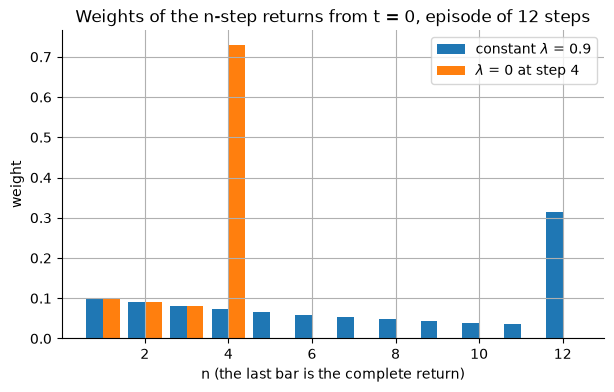

Checkpoint: the variable-lambda weights sum to one, reduce to the constant-lambda weights, and match the trace form


In [30]:
lam_flat = np.full(VAR_T - 1, VAR_LAMBDA)
lam_confident = lam_flat.copy()
lam_confident[VAR_CONFIDENT_STEP - 1] = 0.0  # lambda_{t+VAR_CONFIDENT_STEP} for t = 0
w_flat, w_confident = lambda_weights(lam_flat), lambda_weights(lam_confident)
print(f"Weights on the 1-step, 2-step, ... returns and the complete return, constant lambda = {VAR_LAMBDA}:", np.round(w_flat, 3).tolist())
print(f"... with lambda = 0 at step {VAR_CONFIDENT_STEP}:", np.round(w_confident, 3).tolist())
fig, ax = plt.subplots()
ax.bar(np.arange(1, VAR_T + 1) - BAR_WIDTH / 2, w_flat, BAR_WIDTH, label=f"constant $\\lambda$ = {VAR_LAMBDA}")
ax.bar(np.arange(1, VAR_T + 1) + BAR_WIDTH / 2, w_confident, BAR_WIDTH, label=f"$\\lambda$ = 0 at step {VAR_CONFIDENT_STEP}")
ax.set(xlabel="n (the last bar is the complete return)", ylabel="weight", title=f"Weights of the n-step returns from t = 0, episode of {VAR_T} steps")
ax.legend()
plt.show()
print("Checkpoint: the variable-lambda weights sum to one, reduce to the constant-lambda weights, and match the trace form")

### Reading the result

- The weights sum to one within 2.2e-16, and a constant $\lambda$ gives $(1-\lambda)\lambda^{n-1}$ and $\lambda^{T-t-1}$ within 1.1e-16.
- The weighted returns equal the recursion within 8.9e-16, and the forward updates equal the backward trace updates within 3.6e-15, on all 200 episodes. The variable-$\lambda$ trace is therefore the backward view of the variable-$\lambda$ return.
- With $\lambda_t = 0$ at the non-greedy step, the trace equation reproduces Watkins's traces of the hand-computed example exactly (gap 0).
- For a constant $\lambda = 0.9$ the weights are 0.1, 0.09, 0.081, ... and the complete return holds 0.314, which is $0.9^{11}$. With $\lambda = 0$ at step 4 the weights are 0.1, 0.09, 0.081 and then 0.729 ($= 0.9^3$) on the 4-step return, and exactly 0 for every longer return and the complete return: whatever comes after the trusted state is ignored, as the chapter describes.

## 8. Checkpoints

Every claim above that carries a number is asserted below. Tolerances: $10^{-12}$ for exact arithmetic (hand-computed traces, identities); four standard errors for single sampled comparisons (a two-sided false-alarm chance of about $6 \cdot 10^{-5}$ each; a Bonferroni-style limit divides the allowed total false-alarm chance by the number of comparisons, here 33, so four standard errors keeps the chance of any false alarm near $2 \cdot 10^{-3}$); the same family-wise limit, 0.05 divided by 33, for the one sign test (accumulating against replacing traces); and the Hoeffding limit of the Watkins's Q($\lambda$) section for the cut shares. The demonstration that judging greediness after the update changes results is printed but not asserted.

In [31]:
all_runs = [*sweep.values(), *type_runs.values(), *compared.values()] + [run for runs in table.values() for run in runs.values()]
dutch_limit, accumulating_limit = 1 / (1 - (1 - ALPHA) * GAMMA * LAMBDA), 1 / (1 - GAMMA * LAMBDA)
matched_sweep = {lam: mean_se(speed(run) - speed(sweep[0.0])) for lam, run in sweep.items()}
matched_types = {name: mean_se(speed(run) - speed(type_runs["one-step Sarsa"])) for name, run in type_runs.items()}
watkins_gain = mean_se(speed(watkins) - speed(qlearning))
speedup_ends = (speedup[EPS_GRID[0]], speedup[EPS_GRID[-1]])
checks = [
    ("value iteration gives the book's minimum of 15 steps from the start", abs(-V_opt[windy.start] - OPTIMAL_STEPS) < OPTIMUM_TOL),
    ("a left move from the cell right of the goal lands just above the goal, as the book says", divmod(int(windy.next_state[right_of_goal, LEFT]), len(WIND)) == (WINDY_GOAL[0] - 1, WINDY_GOAL[1])),
    ("the epsilon-greedy-class optimum from value iteration equals a linear solve of its policy", length_gap < LENGTH_TOL),
    (f"the box reproduces the hand-computed traces and values for Sarsa(lambda) and Watkins's Q(lambda) within {EXACT_TOL}", max(hand_error.values()) < EXACT_TOL),
    ("accumulating, replacing, box-dutch and equation-dutch traces take the hand values on a revisited pair", all(abs(v - h) < EXACT_TOL for v, h in revisit.values())),
    ("lambda = 0 equals one-step Sarsa and Q-learning on random trajectories", zero_lambda_error < EXACT_TOL),
    (
        "one-step Sarsa strengthens one pair, Sarsa(lambda) 15, each by alpha (gamma lambda)^k",
        max(trace_error, dutch_equation_error) < EXACT_TOL and (increase["one-step Sarsa"] > 0).sum() == 1 and (increase["Sarsa(lambda), replacing"] > 0).sum() == len(TRACE_PATH),
    ),
    ("no episode is shorter than the optimal 15 steps", min(run.steps.min() for run in all_runs) >= OPTIMAL_STEPS),
    (f"every lambda from 0.3 to 0.95 beats lambda = 0 by more than {Z_LIMIT} standard errors", all(-matched_sweep[lam][0] > Z_LIMIT * matched_sweep[lam][1] for lam in LAMBDAS[1:-1])),
    (f"lambda = {LAMBDAS[-1]} is slower than lambda = 0 by more than {Z_LIMIT} standard errors", matched_sweep[LAMBDAS[-1]][0] > Z_LIMIT * matched_sweep[LAMBDAS[-1]][1]),
    (
        f"replacing and both dutch variants beat one-step Sarsa by more than {Z_LIMIT} standard errors",
        all(-matched_types[k][0] > Z_LIMIT * matched_types[k][1] for k in (f"Sarsa({LAMBDA}), replacing", f"Sarsa({LAMBDA}), dutch", f"Sarsa({LAMBDA}), dutch_equation")),
    ),
    (
        f"accumulating traces are slower than replacing traces in more runs than chance allows (sign test p below {FAMILY_ALPHA} / {N_COMPARISONS})",
        sign_p < FAMILY_ALPHA / N_COMPARISONS and np.median(acc_diff) > 0,
    ),
    (
        "only accumulating traces produce episodes stopped at the step cap",
        type_runs[f"Sarsa({LAMBDA}), accumulating"].n_capped > 0
        and all(type_runs[k].n_capped == 0 for k in ("one-step Sarsa", f"Sarsa({LAMBDA}), replacing", f"Sarsa({LAMBDA}), dutch", f"Sarsa({LAMBDA}), dutch_equation")),
    ),
    (
        "the largest trace stays within the geometric limits 1, 1 / (1 - (1 - alpha) gamma lambda) and 1 / (1 - gamma lambda)",
        type_runs[f"Sarsa({LAMBDA}), replacing"].max_trace == 1.0
        and max(type_runs[f"Sarsa({LAMBDA}), dutch"].max_trace, type_runs[f"Sarsa({LAMBDA}), dutch_equation"].max_trace) <= dutch_limit + TRACE_LIMIT_TOL
        and type_runs[f"Sarsa({LAMBDA}), accumulating"].max_trace <= accumulating_limit + TRACE_LIMIT_TOL,
    ),
    ("the pseudocode and the equation give the same Watkins traces on the example and on random trajectories", max(dataset_gap, box_gap) < EXACT_TOL),
    ("a tie for the maximum counts as greedy: with all values 0 Watkins's traces equal Sarsa's", tie_gap < EXACT_TOL),
]

In [32]:
checks += [
    (f"Watkins's Q({LAMBDA}) beats Q-learning by more than {Z_LIMIT} standard errors", -watkins_gain[0] > Z_LIMIT * watkins_gain[1]),
    (
        "the share of cut steps stays below 3/4 epsilon plus the Hoeffding allowance at every epsilon",
        all(runs["Watkins"].n_cut / runs["Watkins"].n_counted <= 0.75 * eps + np.sqrt(np.log(1 / CUT_DELTA) / (2 * runs["Watkins"].n_counted)) for eps, runs in table.items()),
    ),
    (f"epsilon-greedy picks a non-greedy action with probability 3/4 epsilon (within {Z_LIMIT} standard errors, five comparisons)", all(z < Z_LIMIT for _, z in cut_rates.values())),
    (
        f"the speed-up of Watkins over Q-learning at epsilon = {EPS_GRID[-1]} is smaller than at {EPS_GRID[0]} by more than {Z_LIMIT} standard errors",
        speedup_ends[0][0] - speedup_ends[1][0] > Z_LIMIT * np.hypot(speedup_ends[0][1], speedup_ends[1][1]),
    ),
    (f"... but still above 1 by more than {Z_LIMIT} standard errors", speedup_ends[1][0] - 1 > Z_LIMIT * speedup_ends[1][1]),
    (
        f"the last-{N_LAST}-episode mean never falls below the exact epsilon-greedy-class optimum by more than {Z_LIMIT} standard errors",
        all(last_means(run)[0] + Z_LIMIT * last_means(run)[1] >= -soft_optimal_values(windy, eps)[0][windy.start] for eps, runs in table.items() for run in runs.values()),
    ),
    ("the variable-lambda weights sum to one and reduce to the constant-lambda weights", max(weight_gap, constant_gap) < EXACT_TOL),
    ("the weighted n-step returns equal the recursion, and forward updates equal backward updates", max(recursion_gap, backward_gap) < EXACT_TOL),
    ("Watkins's traces are variable-lambda traces with lambda = 0 at the non-greedy step (consistency of two code paths)", watkins_as_variable < EXACT_TOL),
    ("with lambda = 0 at step 4 no n-step return beyond n = 4 has weight", bool((w_confident[VAR_CONFIDENT_STEP:-1] == 0).all()) and w_confident[-1] == 0),
]
for claim, ok in checks:
    print(("PASS " if ok else "FAIL ") + claim)
assert all(ok for _, ok in checks)

PASS value iteration gives the book's minimum of 15 steps from the start
PASS a left move from the cell right of the goal lands just above the goal, as the book says
PASS the epsilon-greedy-class optimum from value iteration equals a linear solve of its policy
PASS the box reproduces the hand-computed traces and values for Sarsa(lambda) and Watkins's Q(lambda) within 1e-12
PASS accumulating, replacing, box-dutch and equation-dutch traces take the hand values on a revisited pair
PASS lambda = 0 equals one-step Sarsa and Q-learning on random trajectories
PASS one-step Sarsa strengthens one pair, Sarsa(lambda) 15, each by alpha (gamma lambda)^k
PASS no episode is shorter than the optimal 15 steps
PASS every lambda from 0.3 to 0.95 beats lambda = 0 by more than 4 standard errors
PASS lambda = 0.99 is slower than lambda = 0 by more than 4 standard errors
PASS replacing and both dutch variants beat one-step Sarsa by more than 4 standard errors
PASS accumulating traces are slower than replaci

In [33]:
print(f"{'quantity':<66}{'result':>14}{'truth':>10}")
for name, result, truth in [
    ("optimal steps from the start (value iteration)", f"{-V_opt[windy.start]:.0f}", "15"),
    (f"best epsilon-greedy-class length at epsilon = {EPS} (value iteration)", f"{-V_soft[windy.start]:.3f}", "17.048"),
    ("largest gap to the hand-computed example traces and values", f"{max(hand_error.values()):.0e}", "0"),
    ("pair strengthened by Sarsa(lambda), k = 14 steps before the reward", f"{rises[-1]:.4f}", f"{ALPHA_PATH * (GAMMA * LAMBDA_PATH) ** 14:.4f}"),
    (f"Sarsa({LAMBDA}) minus Sarsa(0), steps per episode (run-matched)", f"{matched_sweep[LAMBDA][0]:+.2f}", "< 0"),
    (f"Watkins's Q({LAMBDA}) minus Q-learning, steps per episode (run-matched)", f"{watkins_gain[0]:+.2f}", "< 0"),
    ("pseudocode against equation, largest gap", f"{max(dataset_gap, box_gap):.0e}", "0"),
    ("forward against backward variable-lambda updates, largest gap", f"{backward_gap:.0e}", "0"),
]:
    print(f"{name:<66}{result:>14}{truth:>10}")

quantity                                                                  result     truth
optimal steps from the start (value iteration)                                15        15
best epsilon-greedy-class length at epsilon = 0.1 (value iteration)        17.048    17.048
largest gap to the hand-computed example traces and values                 0e+00         0
pair strengthened by Sarsa(lambda), k = 14 steps before the reward        0.1144    0.1144
Sarsa(0.9) minus Sarsa(0), steps per episode (run-matched)                -23.93       < 0
Watkins's Q(0.9) minus Q-learning, steps per episode (run-matched)        -23.17       < 0
pseudocode against equation, largest gap                                   0e+00         0
forward against backward variable-lambda updates, largest gap              4e-15         0
